# 라이브러리 및 데이터 전처리 부분

In [20]:
# 라이브러리 Import
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

In [21]:
# CSV 파일 로드
df = pd.read_csv('데이터/통합/통합_데이터.csv')

In [22]:
# 신규 개업역의 경우에는 개업일 이후에만 분석하기 위해서 실제 있는 신규 개업역에 대해서 딕셔너리 및 딕셔너리 이용 필터링 함수 선언

# 신규 개업 역 (역명: 개업일)
new_stations = {
    "관악산(서울대)": "2022-05-28",
    "당곡": "2022-05-28",
    "보라매공원": "2022-05-28",
    "보라매병원": "2022-05-28",
    "서울대벤처타운": "2022-05-28",
    "서울지방병무청": "2022-05-28",
    "서원": "2022-05-28",
    "성남": "2024-03-30",
    "암사역사공원": "2024-08-10",
    "원종": "2023-07-01"
}

# 신규 개업역의 개업일 이후 데이터만 필터링
def filter_new_station_data(df, new_stations):
    df_filtered = df.copy()
    for station, open_date in new_stations.items():
        open_date = pd.to_datetime(open_date)
        df_filtered = df_filtered[~((df_filtered['역명'] == station) & (df_filtered['일시'] < open_date))]
    return df_filtered

In [23]:
# 일시를 datetime으로 변환
df['일시'] = pd.to_datetime(df['일시'])

# CSV 데이터 정리 부분

In [24]:
# CSV 데이터 정리

for col in df.columns:
    print(f"열 이름: {col}")
    print(f" - 데이터 타입: {df[col].dtype}")
    print(f" - 결측값 수: {df[col].isnull().sum()}")
    print(f" - 고유값 수: {df[col].nunique()}")
    print(f" - 고유값 예시: {df[col].unique()[:10]}")
    print("-" * 50)

열 이름: 일시
 - 데이터 타입: datetime64[ns]
 - 결측값 수: 0
 - 고유값 수: 1096
 - 고유값 예시: <DatetimeArray>
['2022-01-01 00:00:00', '2022-01-02 00:00:00', '2022-01-03 00:00:00',
 '2022-01-04 00:00:00', '2022-01-05 00:00:00', '2022-01-06 00:00:00',
 '2022-01-07 00:00:00', '2022-01-08 00:00:00', '2022-01-09 00:00:00',
 '2022-01-10 00:00:00']
Length: 10, dtype: datetime64[ns]
--------------------------------------------------
열 이름: 역명
 - 데이터 타입: object
 - 결측값 수: 0
 - 고유값 수: 521
 - 고유값 예시: ['4.19민주묘지' '가능' '가락시장' '가산디지털단지' '가양' '가오리' '가좌' '가천대' '가평' '간석']
--------------------------------------------------
열 이름: 위도
 - 데이터 타입: float64
 - 결측값 수: 0
 - 고유값 수: 521
 - 고유값 예시: [37.649502 37.748577 37.492245 37.480338 37.561391 37.641537 37.568491
 37.448605 37.814536 37.464737]
--------------------------------------------------
열 이름: 경도
 - 데이터 타입: float64
 - 결측값 수: 0
 - 고유값 수: 521
 - 고유값 예시: [127.013684 127.044213 127.117757 126.882656 126.854456 127.016789
 126.915487 127.126697 127.510739 126.694181]
-------------

# 실제 데이터 분석 부분

## 3-1 전체 기준 유입 분석

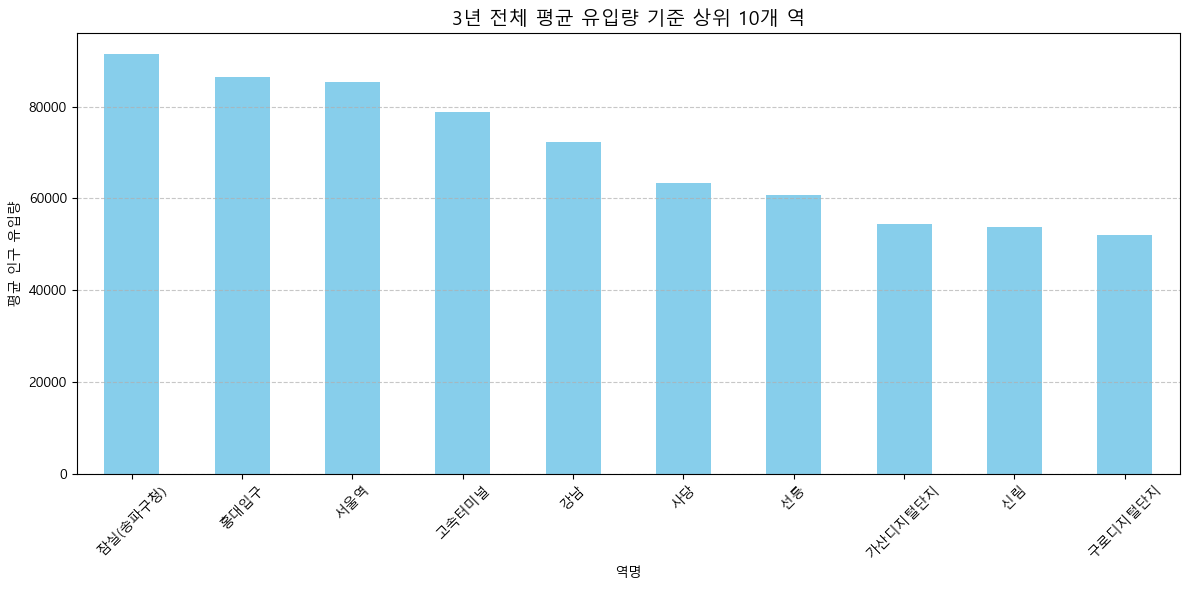

In [25]:
# 3년 전체 기간 동안 평균 유입량이 많은 상위 10개 역을 시각화한 막대그래프

# 1. 신규 개업역 이후 데이터만 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. 역별 평균 유입량 계산
station_avg_inflow = df_filtered.groupby('역명')['인구유입량'].mean().sort_values(ascending=False)

# 3. 상위 10개 역 선택
top10_stations = station_avg_inflow.head(10)

# 4. 시각화 (plt는 이미 import 되어 있음)
plt.figure(figsize=(12, 6))
top10_stations.plot(kind='bar', color='skyblue')
plt.title('3년 전체 평균 유입량 기준 상위 10개 역', fontsize=14)
plt.xlabel('역명')
plt.ylabel('평균 인구 유입량')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 3-2, 3-3 휴일 구분 기준 유입 분석

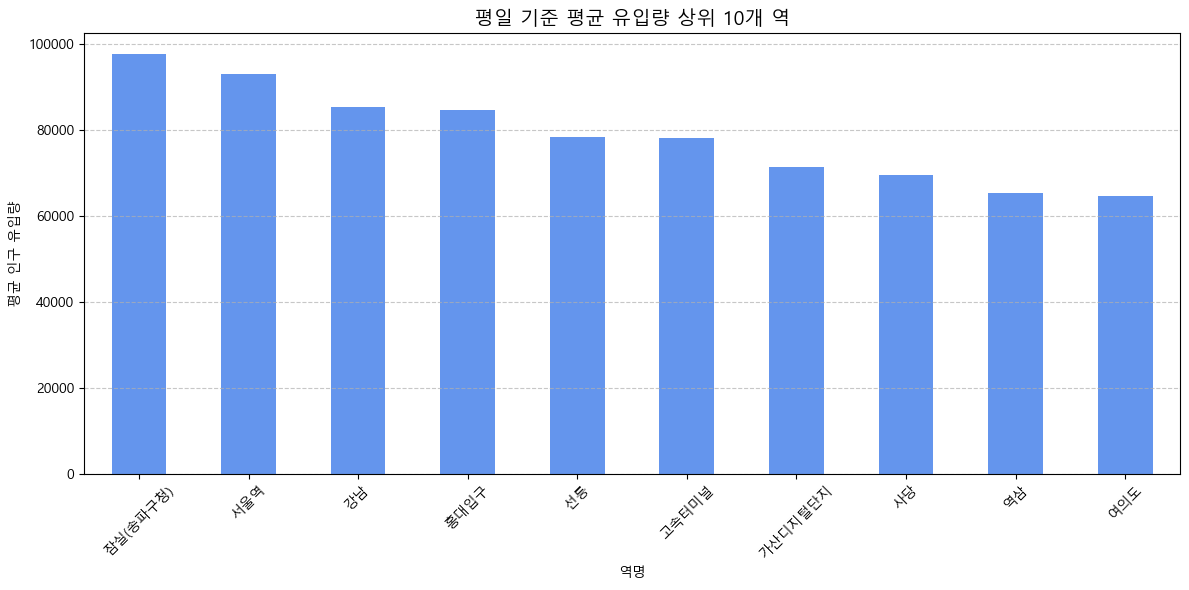

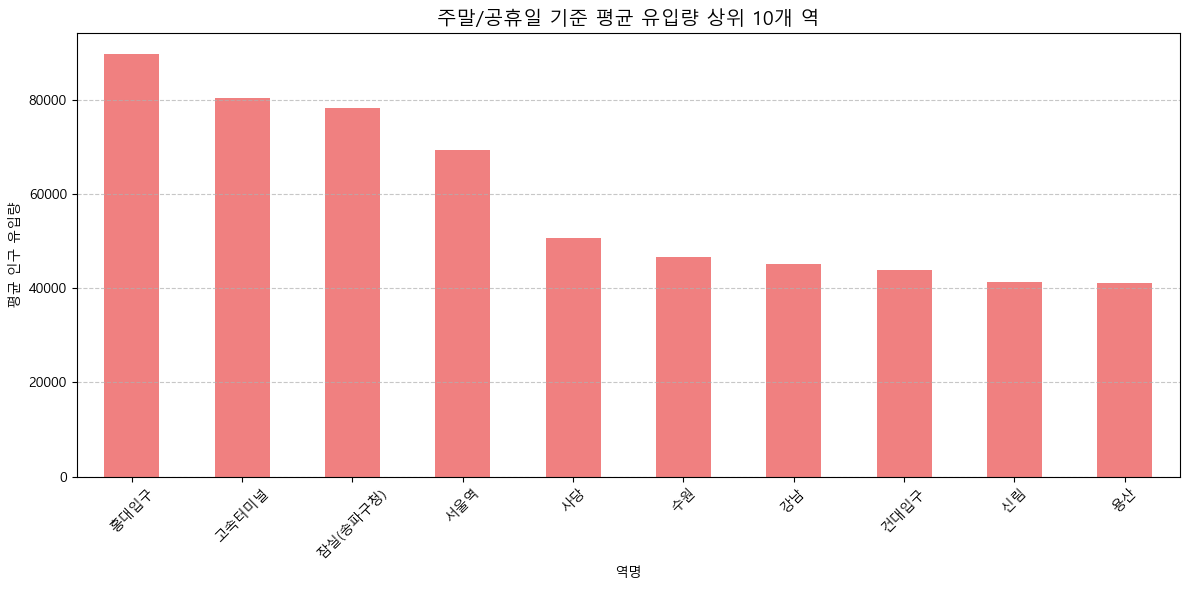

In [26]:
# 3년 전체 기간 동안 휴일 구분(평일 / 주말·공휴일)별 평균 유입량이 많은 상위 10개 역을 시각화한 막대그래프

# 1. 신규 개업역 이후 데이터만 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. '평일'과 '주말/공휴일'로 구분하여 평균 유입량 계산
holiday_groups = df_filtered.groupby(['휴일 구분', '역명'])['인구유입량'].mean()

# 3. 각 구분별 상위 10개 역 추출
weekday_top10 = holiday_groups['평일'].sort_values(ascending=False).head(10)
weekend_top10 = holiday_groups['주말/공휴일'].sort_values(ascending=False).head(10)

# 4. 시각화: 평일
plt.figure(figsize=(12, 6))
weekday_top10.plot(kind='bar', color='cornflowerblue')
plt.title('평일 기준 평균 유입량 상위 10개 역', fontsize=14)
plt.xlabel('역명')
plt.ylabel('평균 인구 유입량')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 5. 시각화: 주말/공휴일
plt.figure(figsize=(12, 6))
weekend_top10.plot(kind='bar', color='lightcoral')
plt.title('주말/공휴일 기준 평균 유입량 상위 10개 역', fontsize=14)
plt.xlabel('역명')
plt.ylabel('평균 인구 유입량')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 3-4. 방학 기준 유입 분석

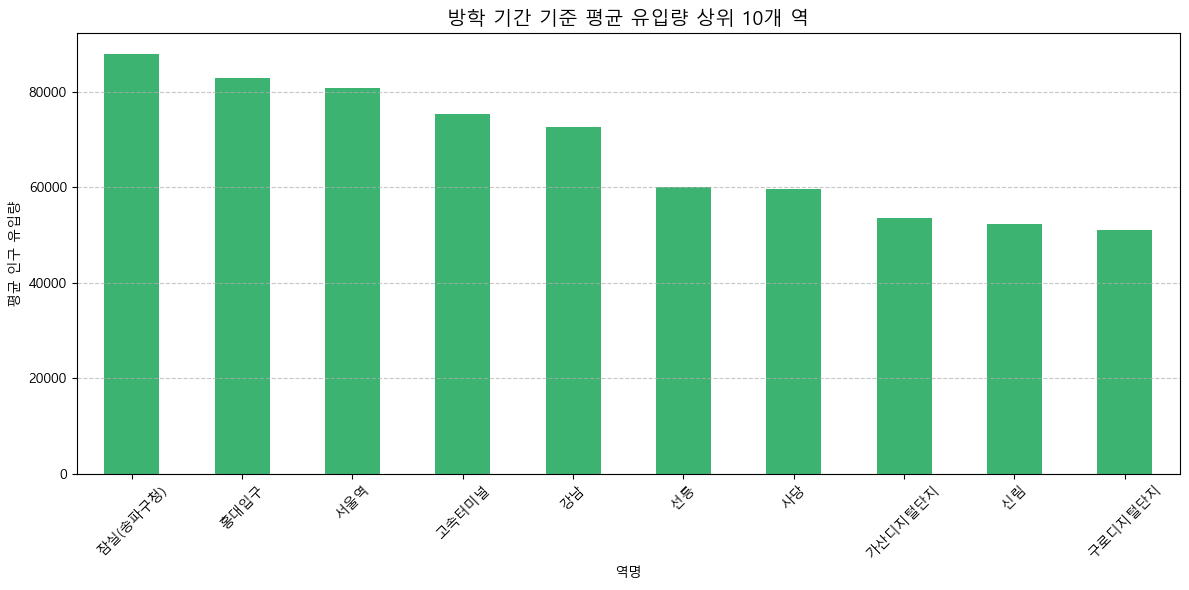

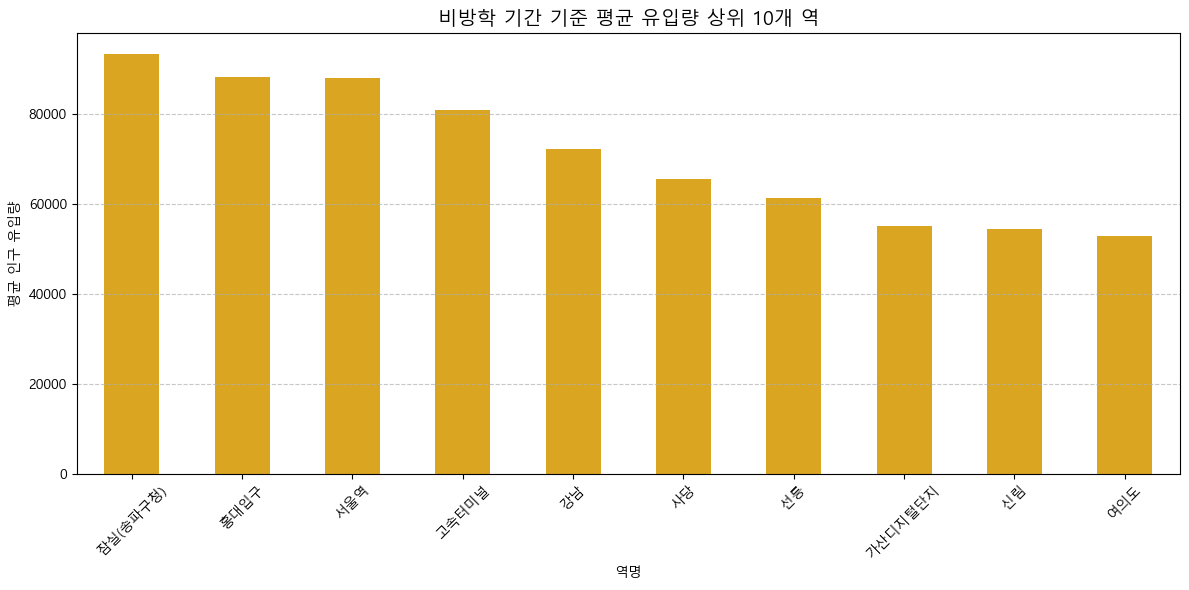

In [27]:
# 3년 전체 기간 중 방학 및 비방학에 평균 유입량이 많은 상위 10개 역을 시각화한 막대그래프

# 1. 신규 개업역 이후 데이터만 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. 방학 및 비방학 조건으로 나누기
vacation_df = df_filtered[df_filtered['방학 여부'].isin(['겨울방학', '여름방학'])]
non_vacation_df = df_filtered[df_filtered['방학 여부'] == 'X']

# 3. 각 그룹별 평균 유입량 계산
vacation_top10 = vacation_df.groupby('역명')['인구유입량'].mean().sort_values(ascending=False).head(10)
non_vacation_top10 = non_vacation_df.groupby('역명')['인구유입량'].mean().sort_values(ascending=False).head(10)

# 4. 방학 기간 시각화
plt.figure(figsize=(12, 6))
vacation_top10.plot(kind='bar', color='mediumseagreen')
plt.title('방학 기간 기준 평균 유입량 상위 10개 역', fontsize=14)
plt.xlabel('역명')
plt.ylabel('평균 인구 유입량')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 5. 비방학 기간 시각화
plt.figure(figsize=(12, 6))
non_vacation_top10.plot(kind='bar', color='goldenrod')
plt.title('비방학 기간 기준 평균 유입량 상위 10개 역', fontsize=14)
plt.xlabel('역명')
plt.ylabel('평균 인구 유입량')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 4-1. 계절 기준 통합 분석(절대, 상대)

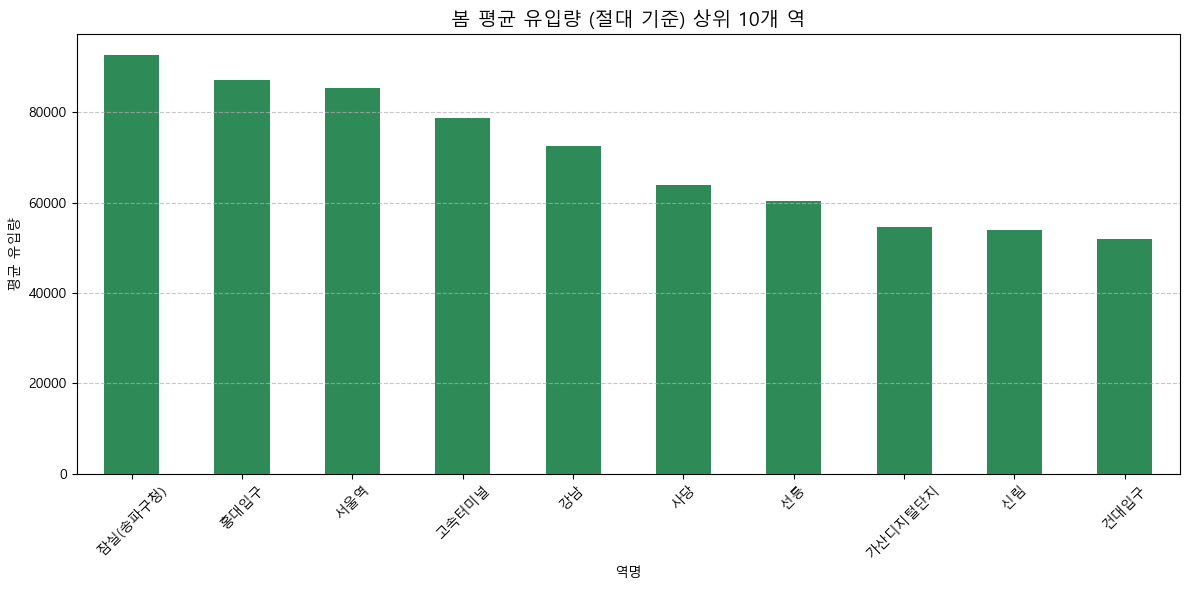

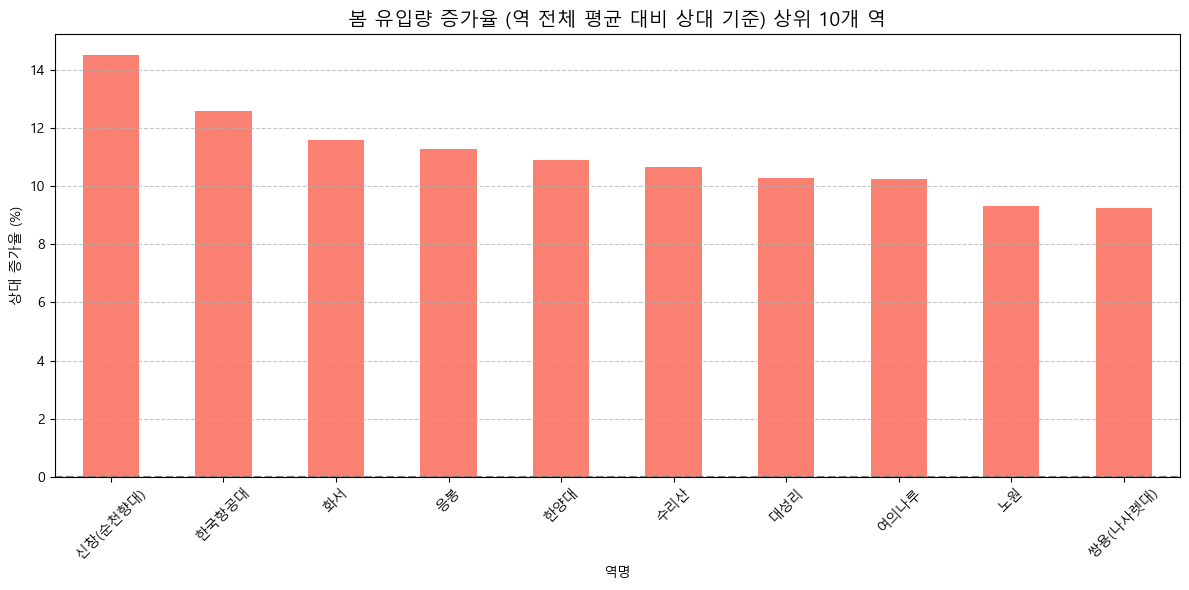

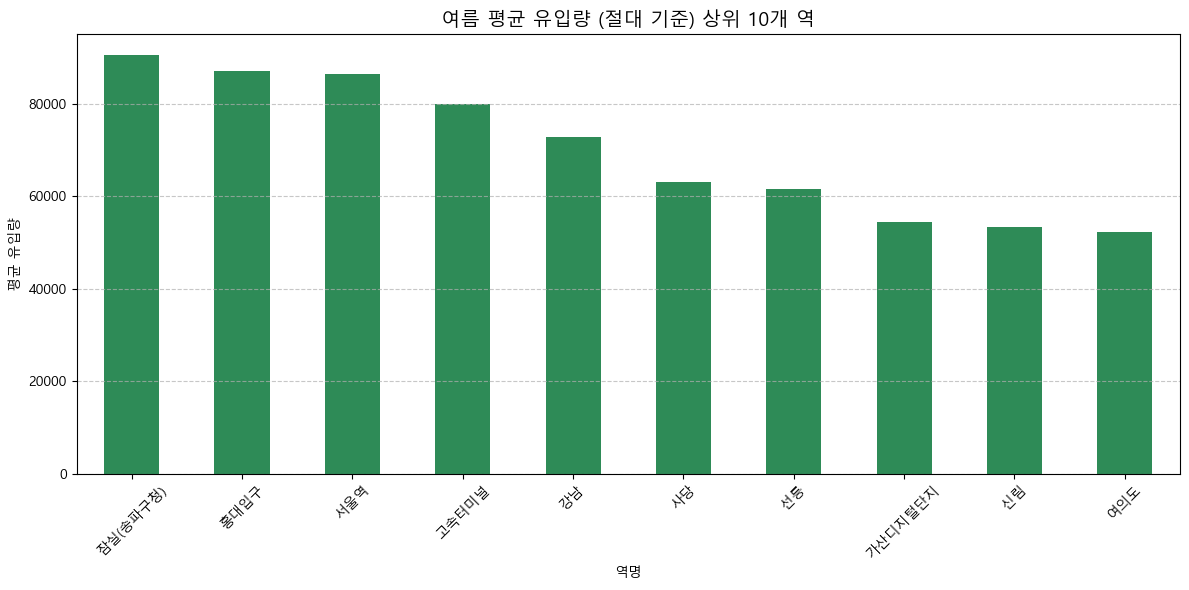

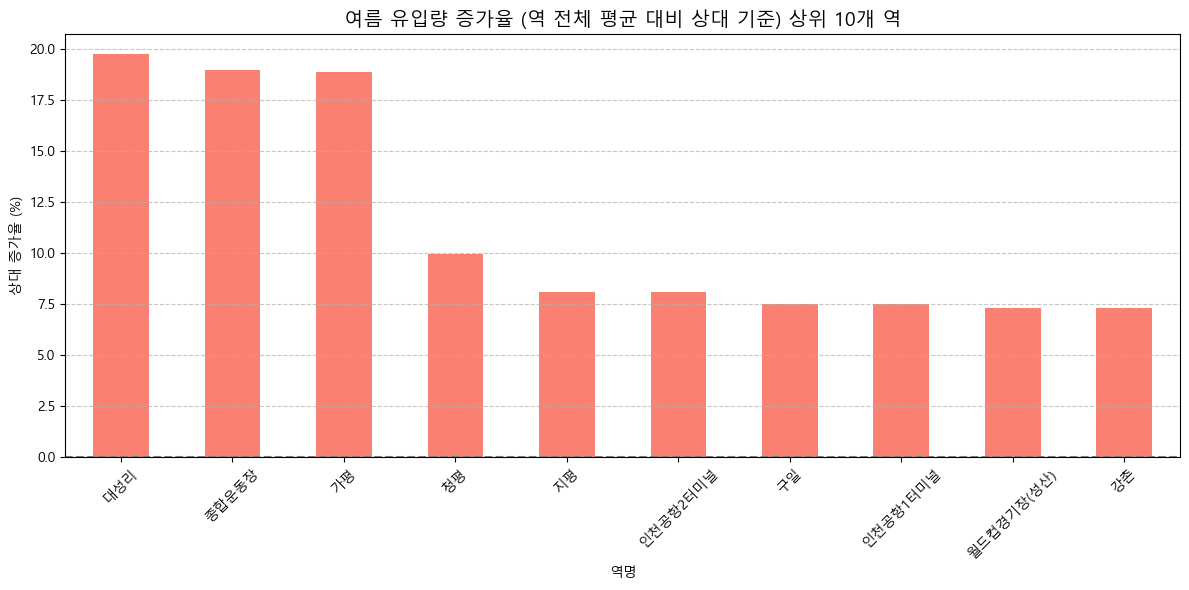

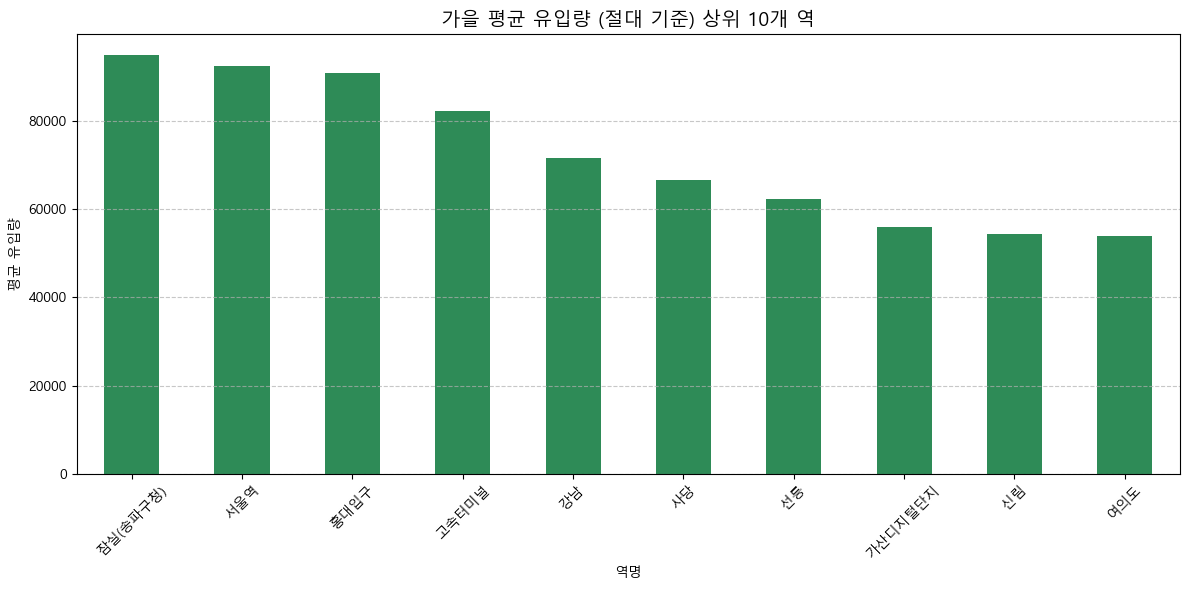

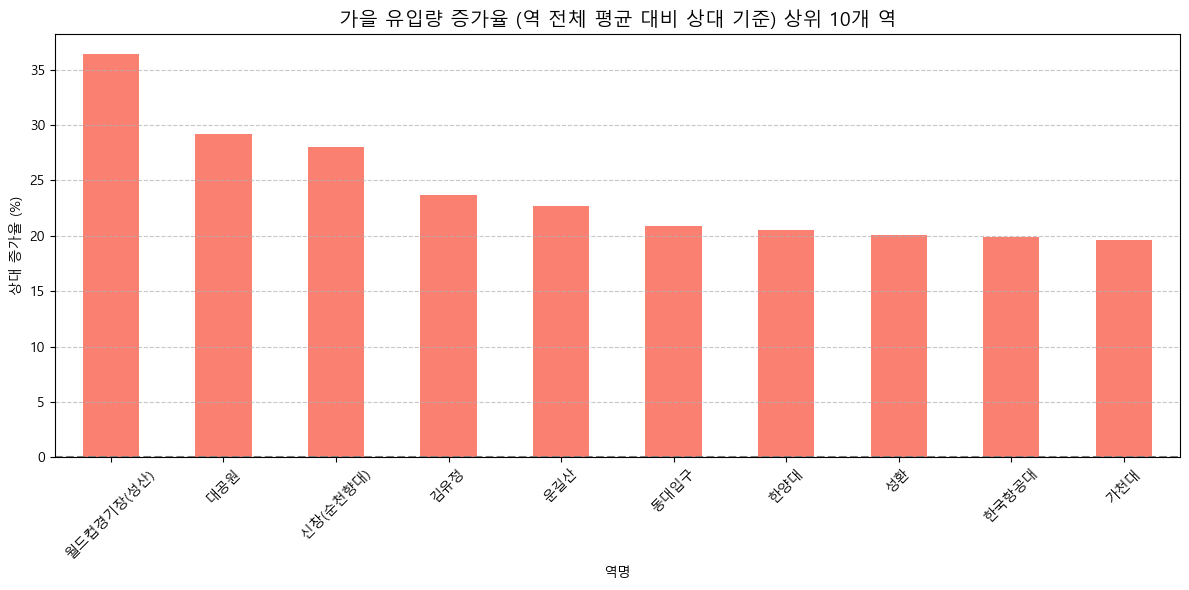

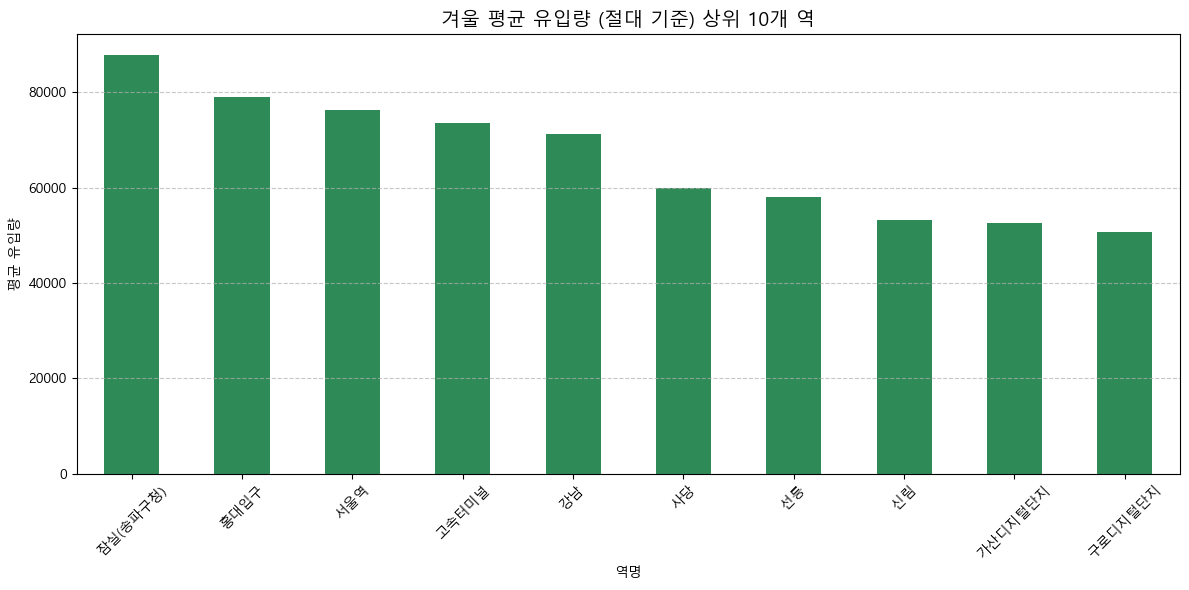

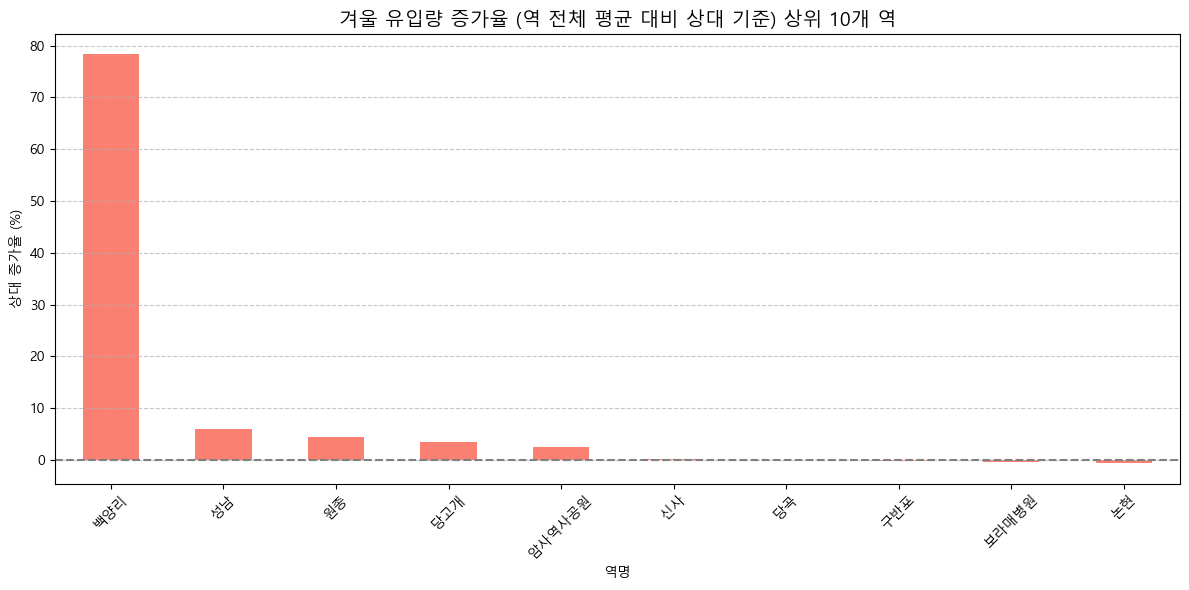

In [28]:
# 계절별로 평균 유입량 기준 (절대)과 전체 평균 대비 상대 증가율 기준 (상대) 모두를 분석하여 각각 상위 10개 역 시각화

# 1. 신규 개업역 이후 데이터 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. 역별 전체 평균 유입량 계산
overall_avg_by_station = df_filtered.groupby('역명')['인구유입량'].mean()

# 3. 계절 리스트
seasons = ['봄', '여름', '가을', '겨울']

# 4. 계절별 분석 반복
for season in seasons:
    # 계절 데이터 추출
    season_df = df_filtered[df_filtered['계절'] == season]
    
    # 절대 유입량 기준 평균 계산 (해당 계절)
    season_avg_by_station = season_df.groupby('역명')['인구유입량'].mean()
    top10_absolute = season_avg_by_station.sort_values(ascending=False).head(10)

    # 상대 유입량 계산용 공통 역 추출
    common_stations = season_avg_by_station.index.intersection(overall_avg_by_station.index)
    
    # 상대 증가율 계산
    relative_growth = (
        (season_avg_by_station[common_stations] - overall_avg_by_station[common_stations]) /
        overall_avg_by_station[common_stations]
    ) * 100
    top10_relative = relative_growth.sort_values(ascending=False).head(10)

    # 시각화 - 절대 기준
    plt.figure(figsize=(12, 6))
    top10_absolute.plot(kind='bar', color='seagreen')
    plt.title(f'{season} 평균 유입량 (절대 기준) 상위 10개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('평균 유입량')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # 시각화 - 상대 기준
    plt.figure(figsize=(12, 6))
    top10_relative.plot(kind='bar', color='salmon')
    plt.title(f'{season} 유입량 증가율 (역 전체 평균 대비 상대 기준) 상위 10개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('상대 증가율 (%)')
    plt.axhline(0, color='gray', linestyle='--')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


## 4-2. 휴일 구분 기준 통합 분석(절대, 상대)

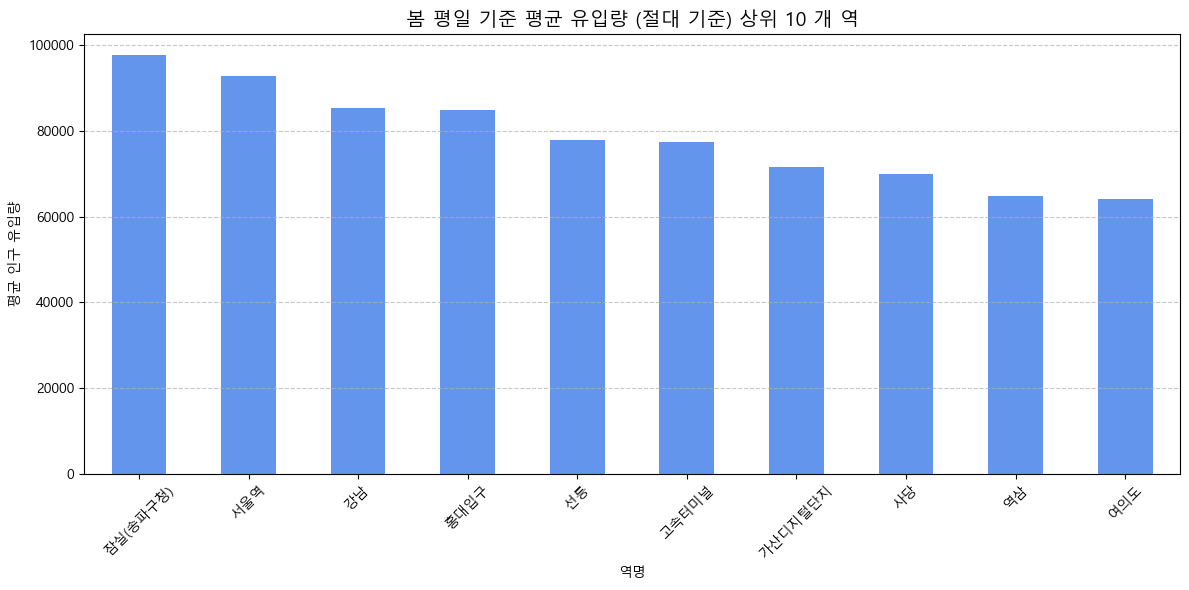

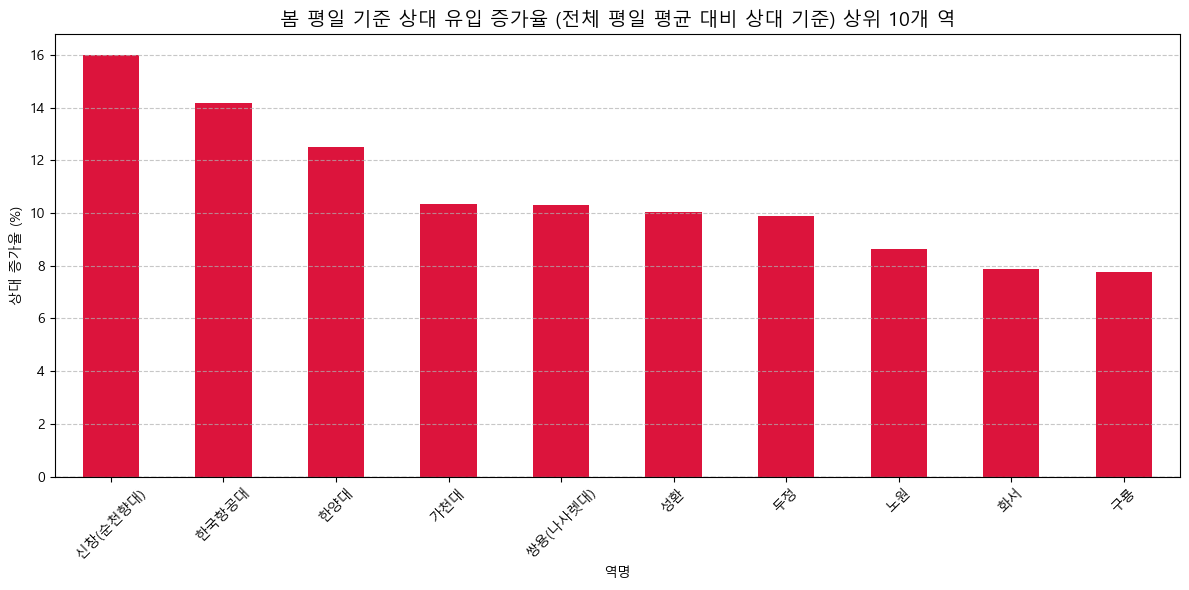

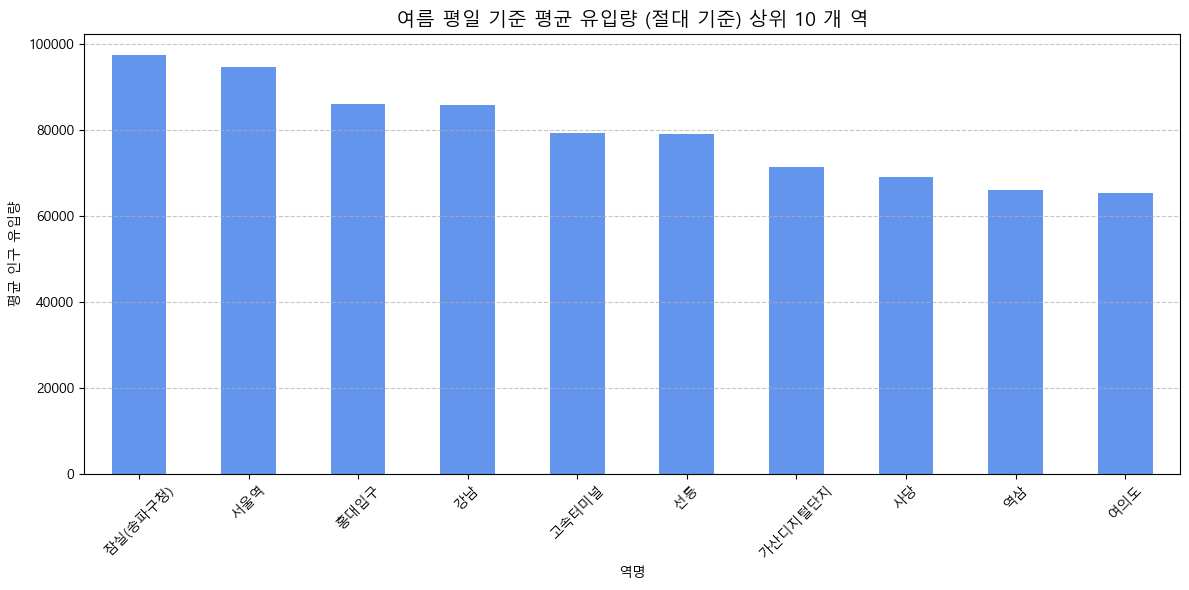

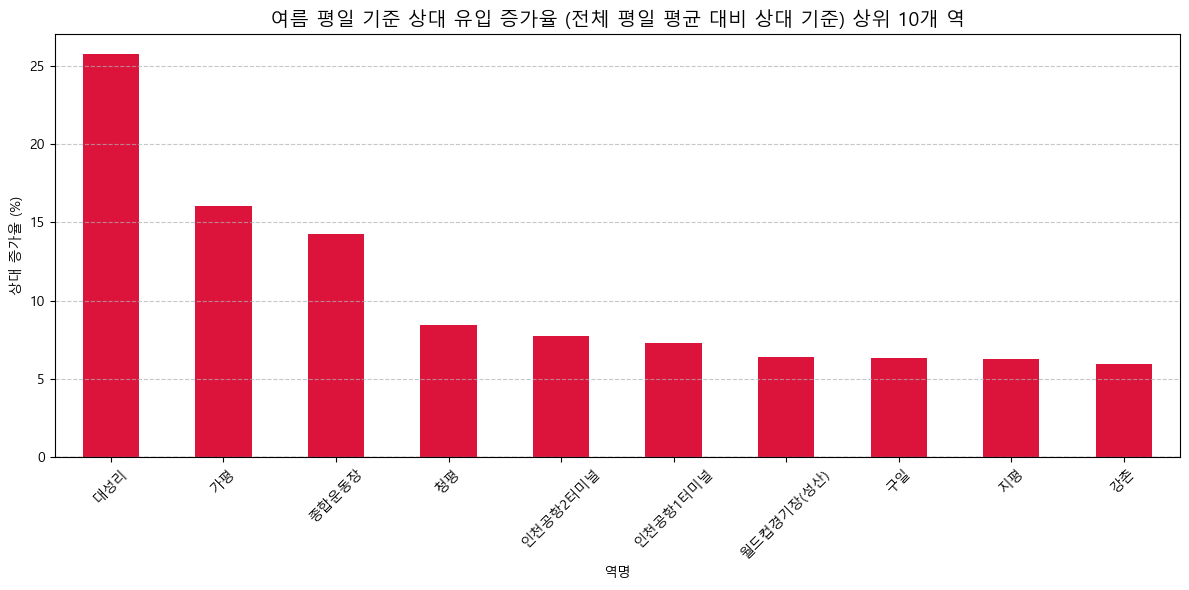

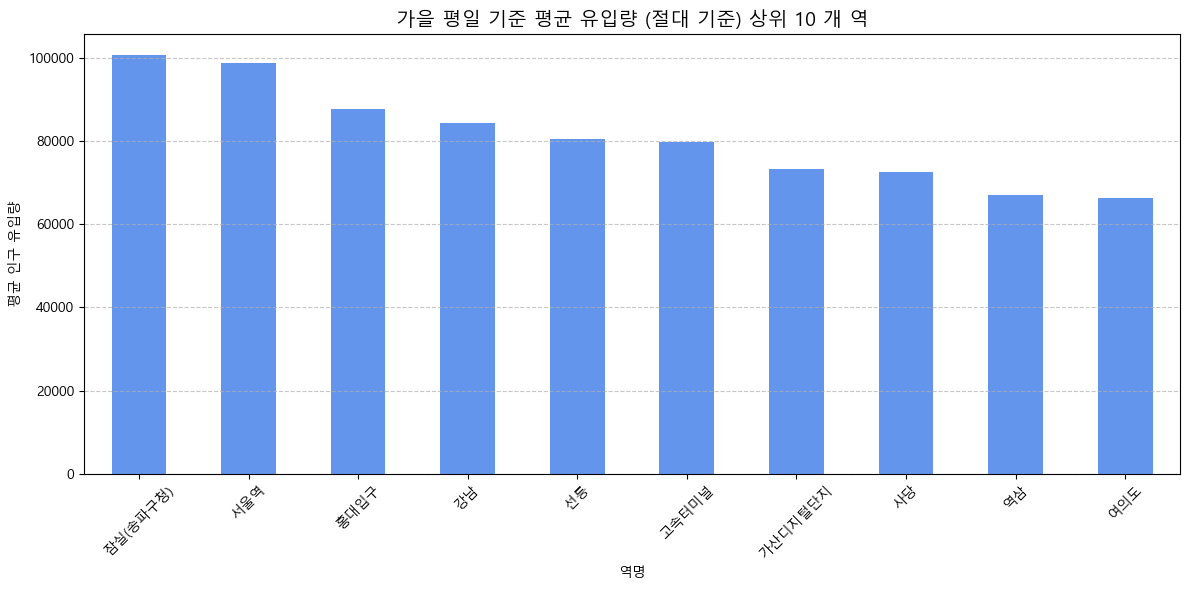

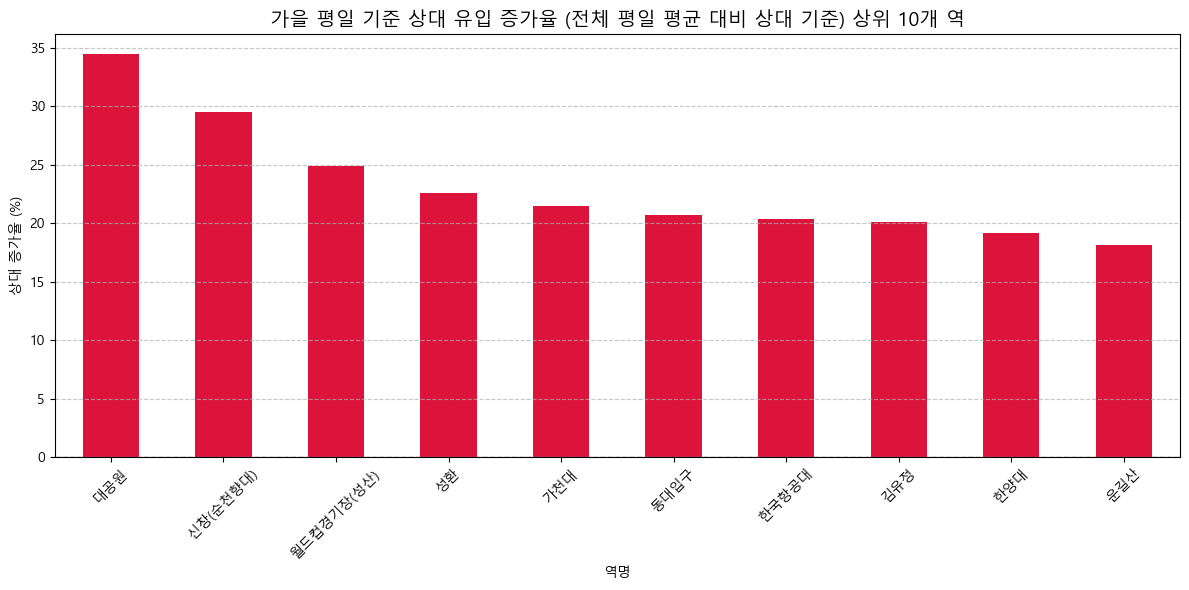

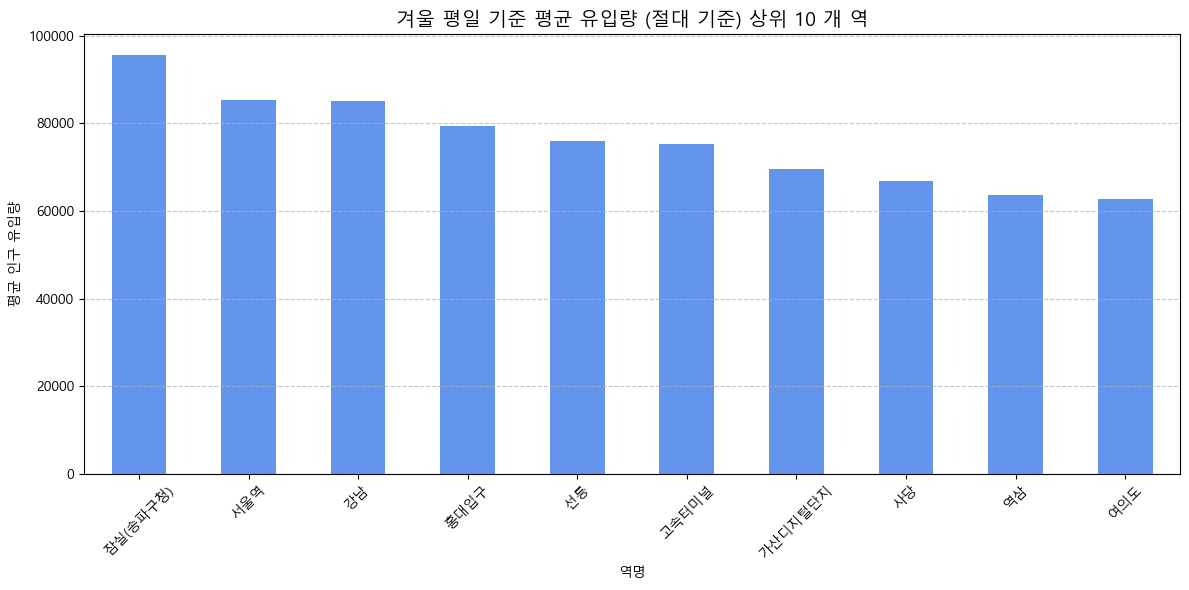

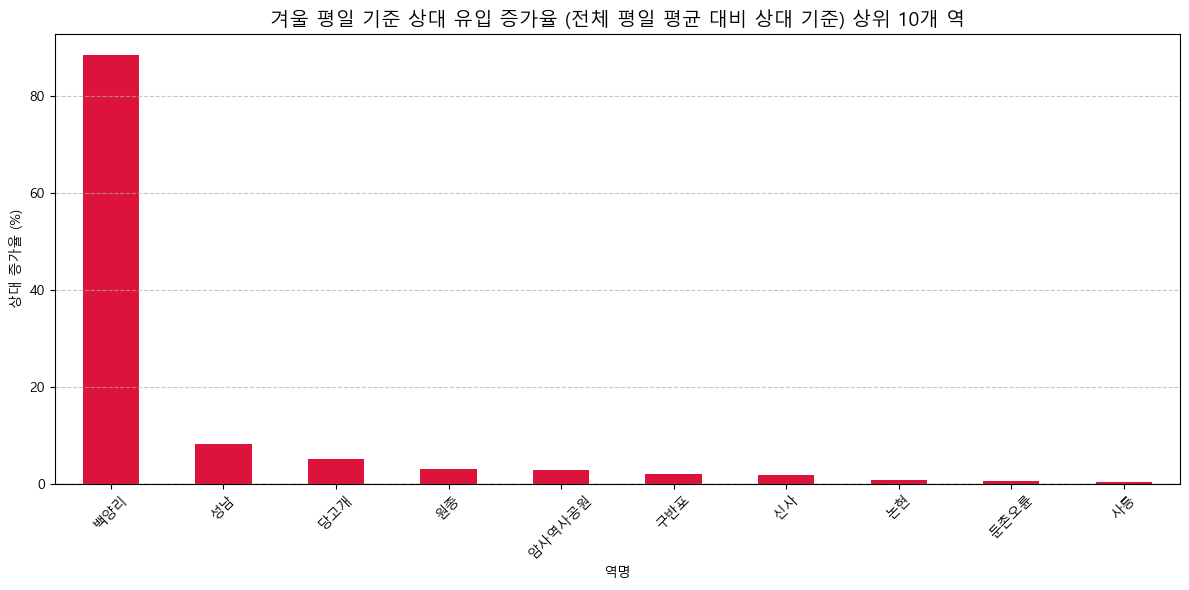

In [30]:
# 1. 신규 개업역 이후 데이터 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. 전체 평일 기준 평균 유입량 계산 (비교 기준선)
weekday_total_avg = df_filtered[df_filtered['휴일 구분'] == '평일'].groupby('역명')['인구유입량'].mean()

# 3. 계절 리스트
seasons = ['봄', '여름', '가을', '겨울']

# 4. 계절별 분석
for season in seasons:
    # 계절 + 평일 필터링
    season_weekday_df = df_filtered[
        (df_filtered['계절'] == season) & (df_filtered['휴일 구분'] == '평일')
    ]

    # 계절+평일 기준 역별 평균 유입량
    season_weekday_avg = season_weekday_df.groupby('역명')['인구유입량'].mean()
    top10_absolute = season_weekday_avg.sort_values(ascending=False).head(10)

    # 공통 역 추출
    common_stations = season_weekday_avg.index.intersection(weekday_total_avg.index)

    # 상대 유입 증가율 계산 (계절-평일 기준 vs 전체-평일 기준)
    relative_growth = (
        (season_weekday_avg[common_stations] - weekday_total_avg[common_stations]) /
        weekday_total_avg[common_stations]
    ) * 100
    top10_relative = relative_growth.sort_values(ascending=False).head(10)

    # === 시각화: 절대 기준 ===
    plt.figure(figsize=(12, 6))
    top10_absolute.plot(kind='bar', color='cornflowerblue')
    plt.title(f'{season} 평일 기준 평균 유입량 (절대 기준) 상위 10 개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('평균 인구 유입량')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # === 시각화: 상대 기준 ===
    plt.figure(figsize=(12, 6))
    top10_relative.plot(kind='bar', color='crimson')
    plt.title(f'{season} 평일 기준 상대 유입 증가율 (전체 평일 평균 대비 상대 기준) 상위 10개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('상대 증가율 (%)')
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

## 4-3. 계절별 주말/공휴일 구분 기준 통합 분석(절대, 상대)

[봄] 상대 증가율 상위 10개 역: ['응봉', '대성리', '수리산', '화서', '서울숲', '성남', '자양(뚝섬한강공원)', '여의나루', '학여울', '상천']


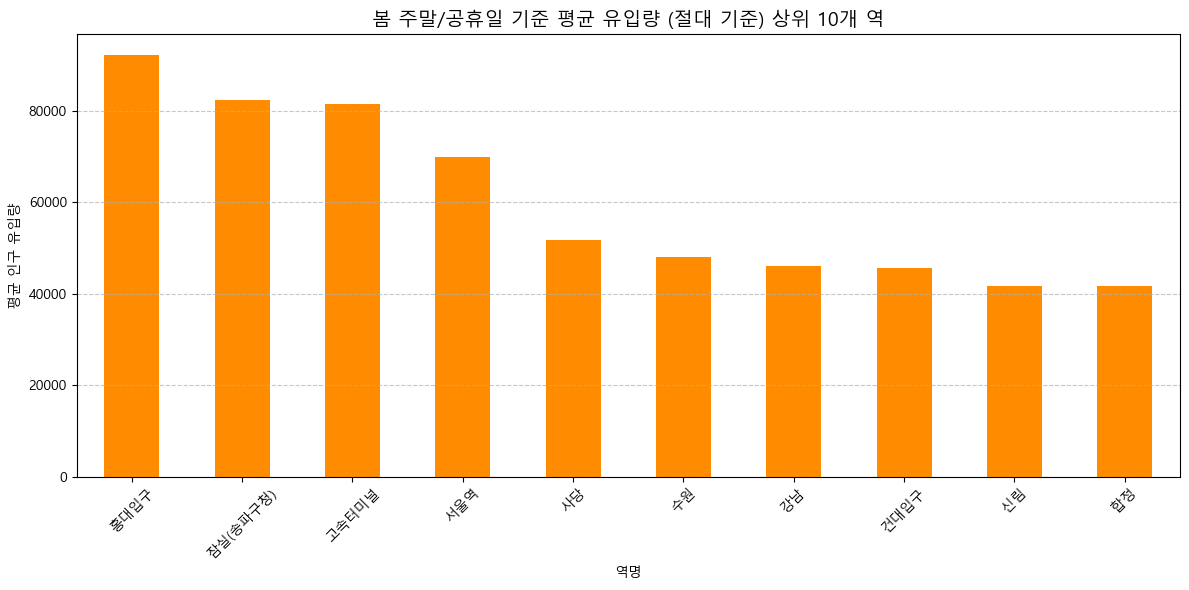

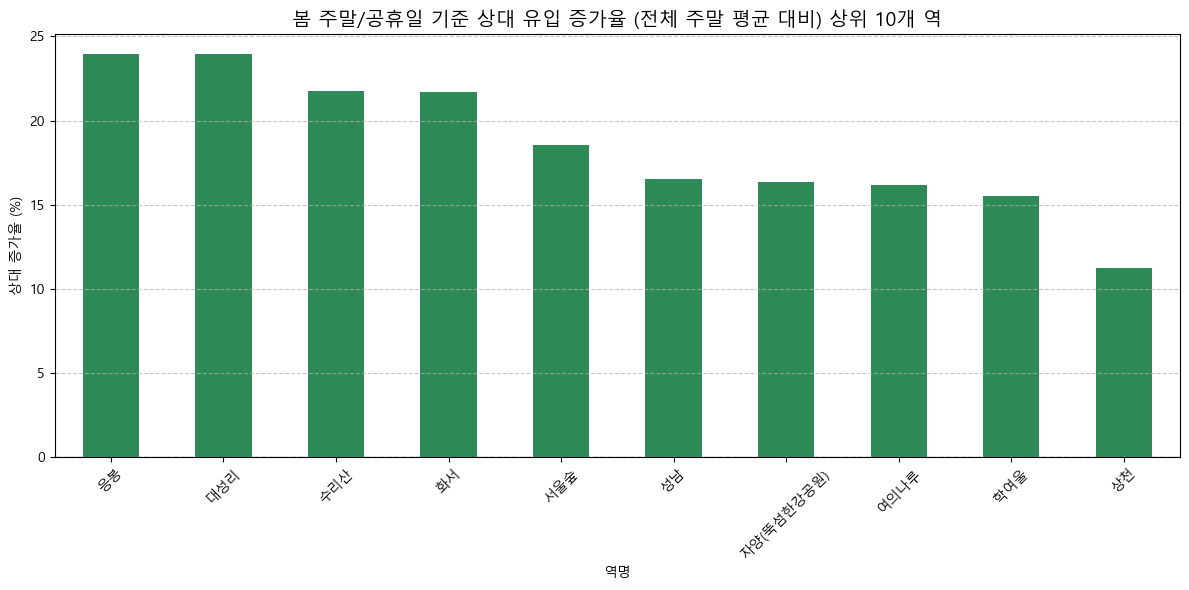

[여름] 상대 증가율 상위 10개 역: ['종합운동장', '가평', '청평', '지평', '관악산(서울대)', '대성리', '구일', '양수', '강촌', '동작(현충원)']


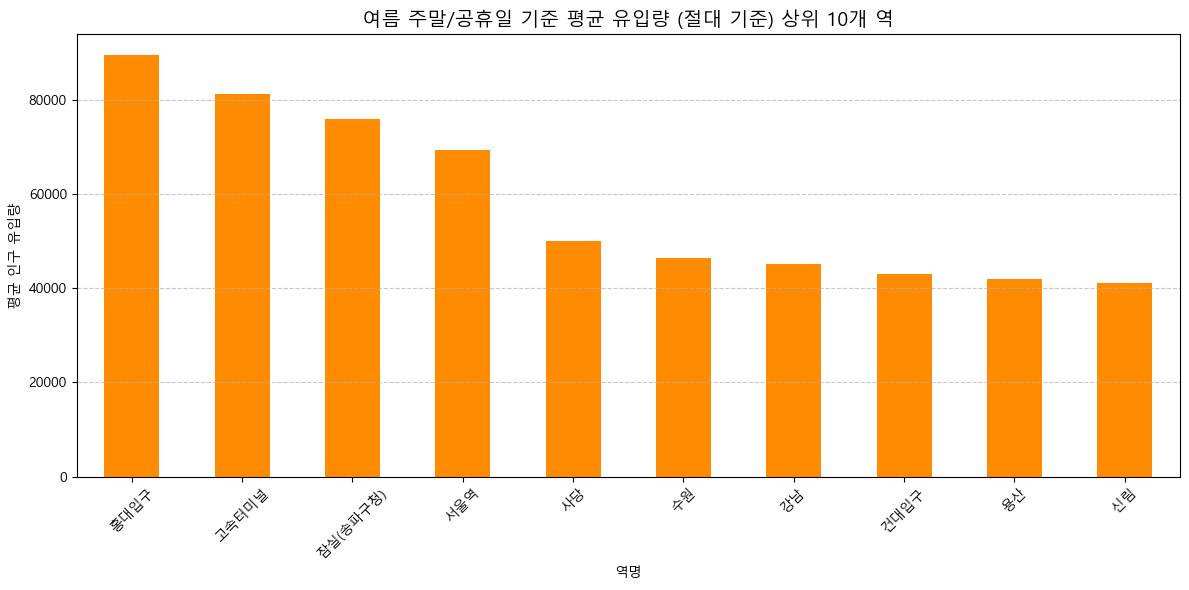

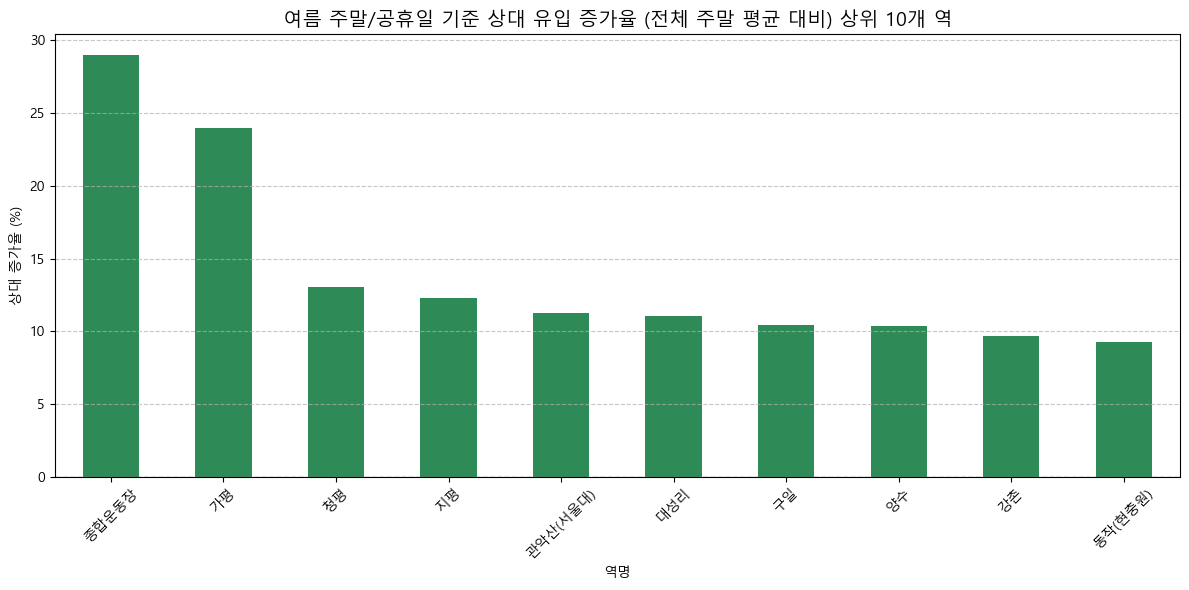

[가을] 상대 증가율 상위 10개 역: ['월드컵경기장(성산)', '한양대', '경복궁(정부서울청사)', '시청', '여의나루', '운길산', '김유정', '노들', '서빙고', '소래포구']


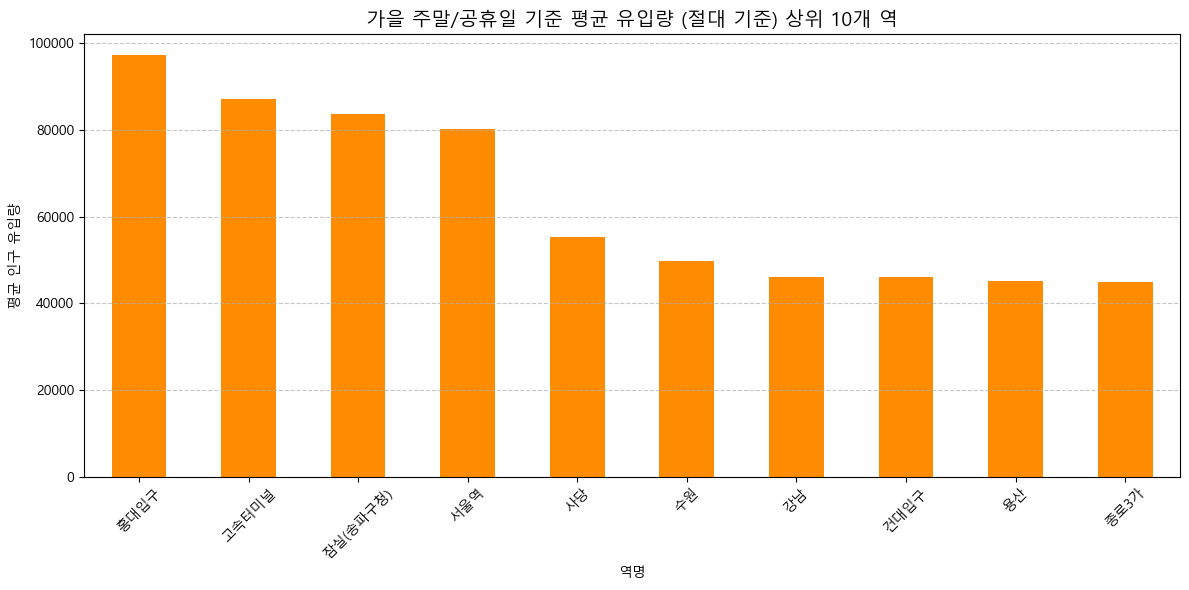

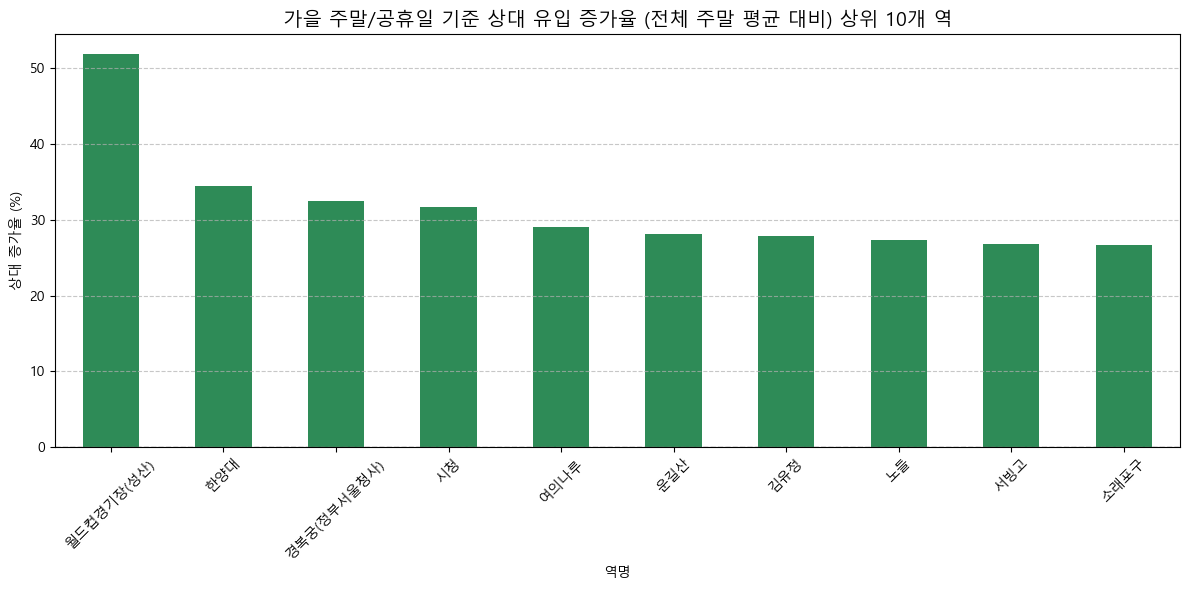

[겨울] 상대 증가율 상위 10개 역: ['백양리', '남태령', '원종', '당고개', '신길', '국회의사당', '당곡', '성남', '샛강', '신림']


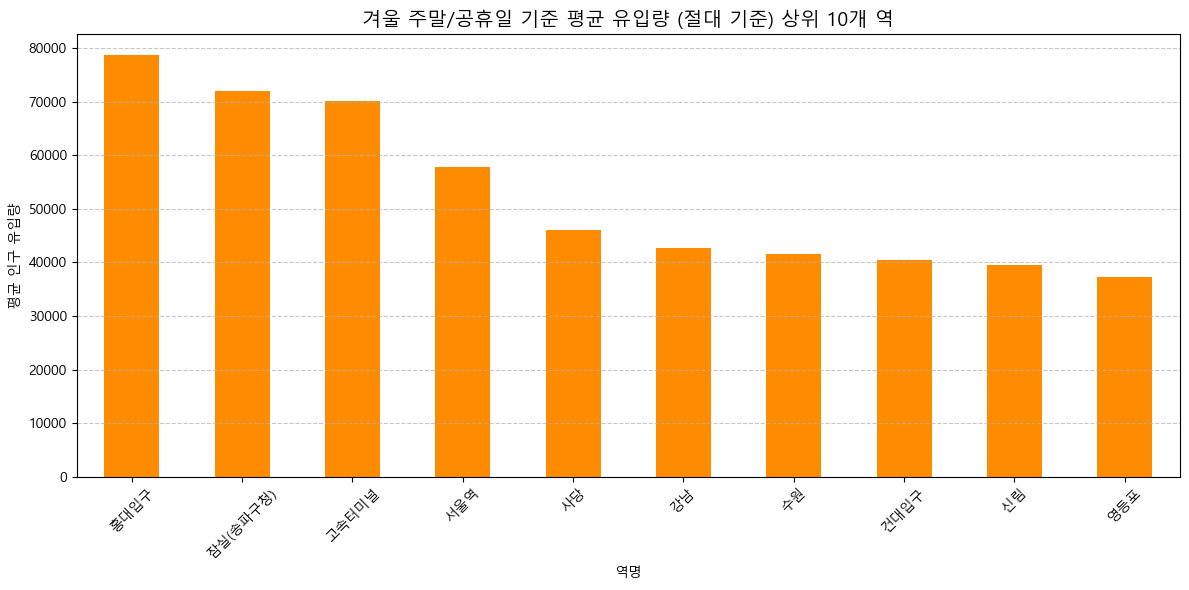

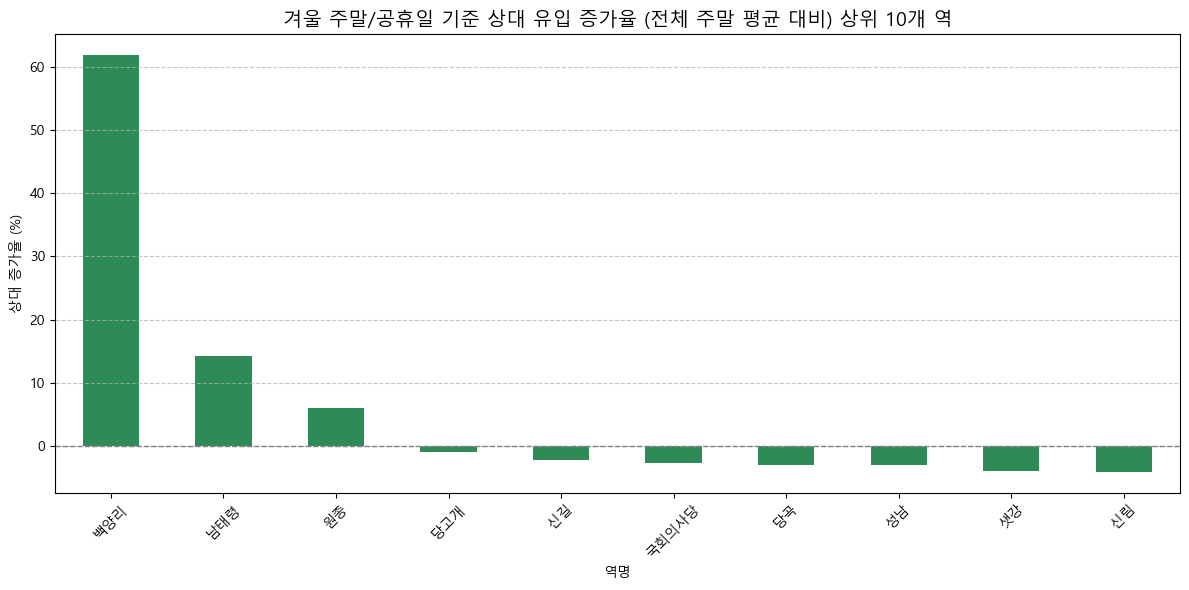

In [31]:
# 1. 신규 개업역 이후 데이터 필터링
df_filtered = filter_new_station_data(df, new_stations)

# 2. 전체 주말/공휴일 기준 평균 유입량 계산 (비교 기준선)
weekend_total_avg = df_filtered[df_filtered['휴일 구분'] == '주말/공휴일'].groupby('역명')['인구유입량'].mean()

# 3. 계절 리스트
seasons = ['봄', '여름', '가을', '겨울']

# 4. 계절별 분석
for season in seasons:
    # 계절 + 주말/공휴일 필터링
    season_weekend_df = df_filtered[
        (df_filtered['계절'] == season) & (df_filtered['휴일 구분'] == '주말/공휴일')
    ]

    # 계절+주말 기준 역별 평균 유입량
    season_weekend_avg = season_weekend_df.groupby('역명')['인구유입량'].mean()
    top10_absolute = season_weekend_avg.sort_values(ascending=False).head(10)

    # 공통 역 추출
    common_stations = season_weekend_avg.index.intersection(weekend_total_avg.index)

    # 상대 유입 증가율 계산 (계절-주말 기준 vs 전체-주말 기준)
    relative_growth = (
        (season_weekend_avg[common_stations] - weekend_total_avg[common_stations]) /
        weekend_total_avg[common_stations]
    ) * 100
    top10_relative = relative_growth.sort_values(ascending=False).head(10)
    # ✅ 상위 10개 역 이름 출력
    #print(f"[{season}] 절대 유입량 상위 10개 역:", list(top10_absolute.index))
    print(f"[{season}] 상대 증가율 상위 10개 역:", list(top10_relative.index))

    # === 시각화: 절대 기준 ===
    plt.figure(figsize=(12, 6))
    top10_absolute.plot(kind='bar', color='darkorange')
    plt.title(f'{season} 주말/공휴일 기준 평균 유입량 (절대 기준) 상위 10개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('평균 인구 유입량')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # === 시각화: 상대 기준 ===
    plt.figure(figsize=(12, 6))
    top10_relative.plot(kind='bar', color='seagreen')
    plt.title(f'{season} 주말/공휴일 기준 상대 유입 증가율 (전체 주말 평균 대비) 상위 10개 역', fontsize=14)
    plt.xlabel('역명')
    plt.ylabel('상대 증가율 (%)')
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


## 5-1. 봄 날씨 유형 구분 기준 통합분석(절대, 상대)

In [32]:

# 계절 리스트
seasons = ['봄', '여름', '가을', '겨울']

# 결과 저장용 딕셔너리
season_weather_summary = {}

# 계절별 처리
for season in seasons:
    # 계절 + 주말/공휴일 필터링
    season_weekend_df = df_filtered[
        (df_filtered['계절'] == season) & (df_filtered['휴일 구분'] == '주말/공휴일')
    ]
    
    # 중복되지 않은 날짜-날씨 조합만 남김
    weather_day_counts = season_weekend_df[['일시', '날씨 유형']].drop_duplicates()
    
    # 날씨 유형별 일수 계산
    weather_counts = weather_day_counts['날씨 유형'].value_counts()
    
    # 고유 날짜 수
    unique_days = season_weekend_df['일시'].dt.date.nunique()
    
    # 결과 저장
    season_weather_summary[season] = {
        '고유 날짜 수': unique_days,
        '날씨 유형별 일수': weather_counts.to_dict()
    }

season_weather_summary


{'봄': {'고유 날짜 수': 101,
  '날씨 유형별 일수': {'맑음': 39,
   '보통': 25,
   '강우': 14,
   '흐림': 9,
   '적설': 8,
   '대설': 4,
   '약우': 2}},
 '여름': {'고유 날짜 수': 127,
  '날씨 유형별 일수': {'보통': 49, '강우': 36, '고습': 15, '맑음': 11, '흐림': 9, '약우': 7}},
 '가을': {'고유 날짜 수': 64,
  '날씨 유형별 일수': {'맑음': 28, '보통': 16, '강우': 8, '흐림': 6, '약우': 4, '대설': 2}},
 '겨울': {'고유 날짜 수': 64,
  '날씨 유형별 일수': {'맑음': 26, '보통': 18, '적설': 13, '흐림': 3, '약우': 3, '대설': 1}}}

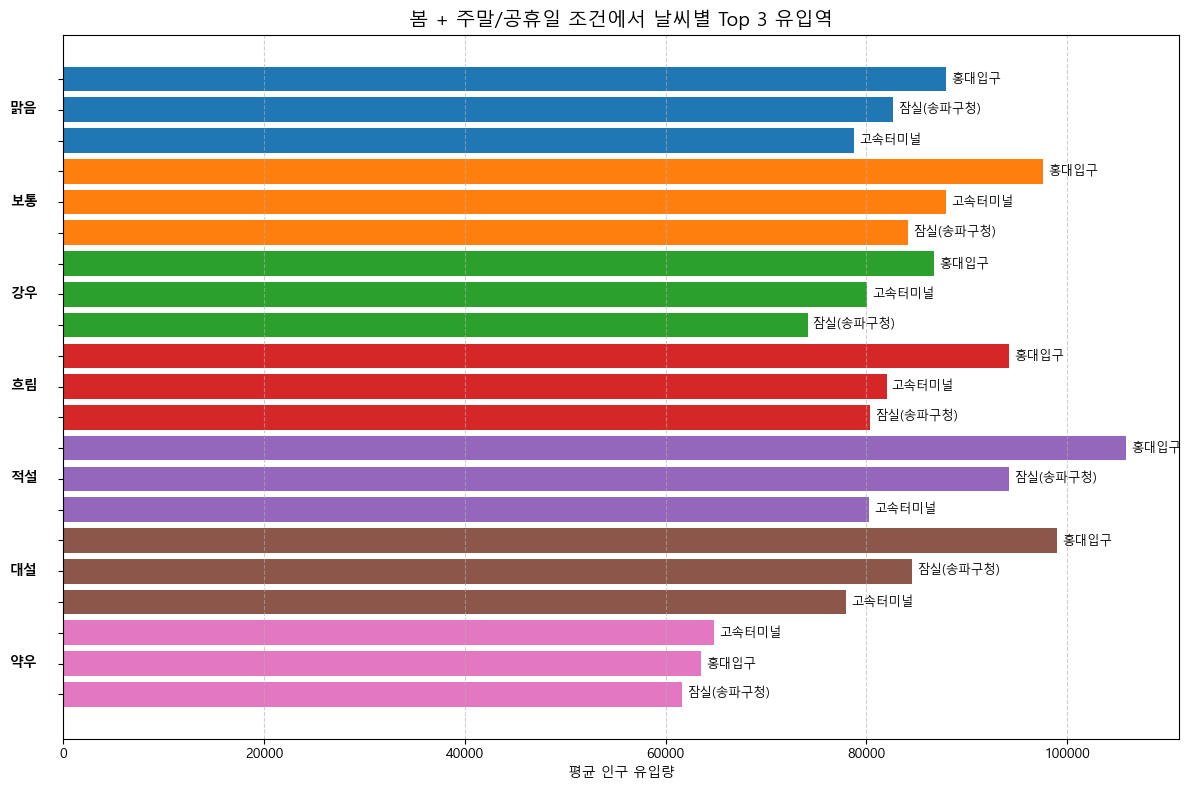

In [33]:

# ② 조건: 봄 + 주말/공휴일 필터링
spring_weekend_df = df_filtered[
    (df_filtered['계절'] == '봄') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 날씨 유형별 Top 3 유입역 추출
weather_order = ['맑음', '보통', '강우', '흐림', '적설', '대설', '약우']
top3_data = []

for weather in weather_order:
    weather_df = spring_weekend_df[spring_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()
    top3 = avg_by_station.sort_values(ascending=False).head(3)
    for rank, (station, value) in enumerate(top3.items(), start=1):
        top3_data.append({
            '날씨': weather,
            '역명': station,
            '유입량': value,
            '순위': rank
        })

# ④ 데이터프레임 변환
top3_df = pd.DataFrame(top3_data)

# ⑤ 시각화: 막대그래프 (가로 막대, 역명 표시 포함)
plt.figure(figsize=(12, 8))

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '적설': '#9467bd',
    '대설': '#8c564b',
    '약우': '#e377c2',
}

yticks = []
yticklabels = []
bar_positions = []

# ⑦ 막대 출력
for i, weather in enumerate(weather_order):
    group = top3_df[top3_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['유입량'], color=weather_colors[weather])
        plt.text(row['유입량'] + 500, y_pos, row['역명'], va='center', fontsize=9)  # 오른쪽에 역명
        bar_positions.append(y_pos)
     

# ⑧ y축 설정 및 정렬
plt.yticks(bar_positions, yticklabels)
plt.gca().invert_yaxis()
plt.xlabel('평균 인구 유입량')
plt.title('봄 + 주말/공휴일 조건에서 날씨별 Top 3 유입역', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(top3_df['유입량']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [34]:
# 1. 조건 필터링: 봄 + 주말/공휴일 + 적설
condition_df = df_filtered[
    (df_filtered['계절'] == '봄') &
    (df_filtered['휴일 구분'] == '주말/공휴일') &
    (df_filtered['날씨 유형'] == '약우')
]

# 2. 평균 유입량 기준 정렬
avg_by_station = condition_df.groupby('역명')['인구유입량'].mean()
top_station = avg_by_station.sort_values(ascending=False).head(1)

# 3. 결과 출력
print("🌨️ 봄 + 주말/공휴일 + 적설 조건에서 유입량이 가장 많은 역:")
print(top_station)


🌨️ 봄 + 주말/공휴일 + 적설 조건에서 유입량이 가장 많은 역:
역명
고속터미널    64877.0
Name: 인구유입량, dtype: float64


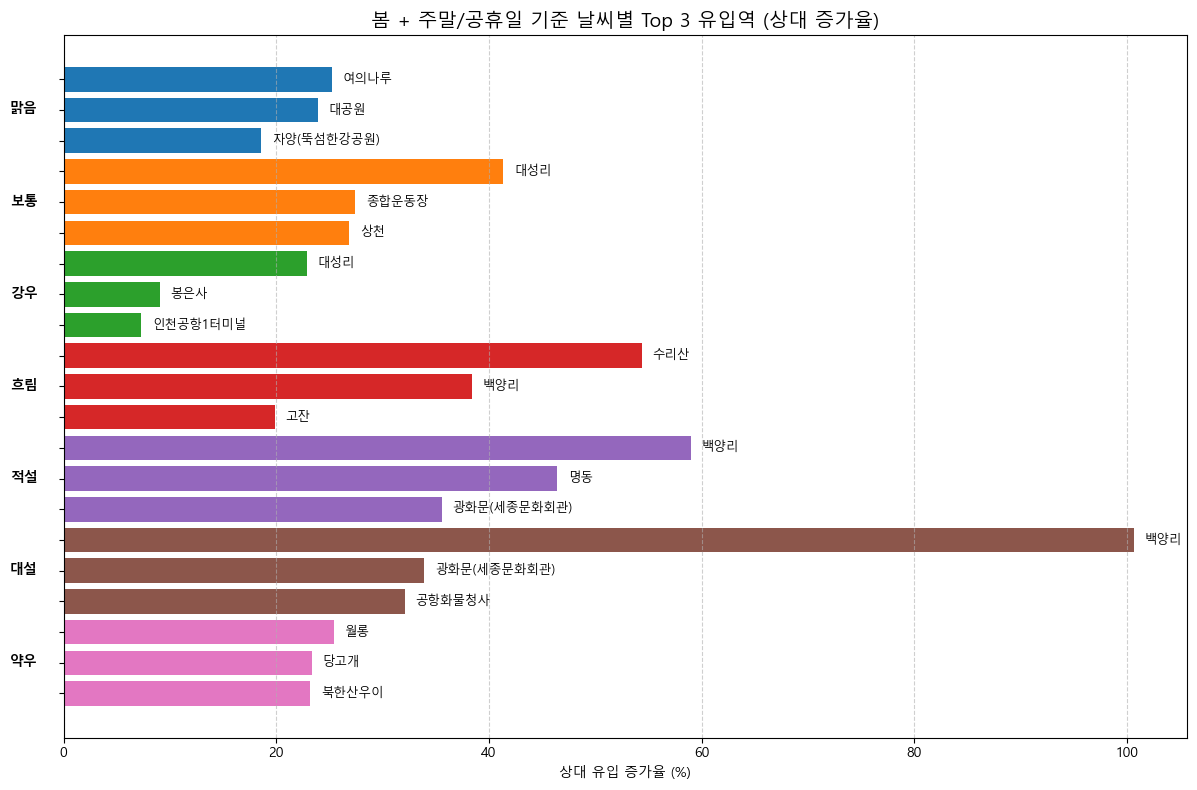

In [35]:
# ② 조건: 봄 + 주말/공휴일 필터링
spring_weekend_df = df_filtered[
    (df_filtered['계절'] == '봄') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 기준선: 봄+주말/공휴일 전체 평균 유입량
spring_avg_all = spring_weekend_df.groupby('역명')['인구유입량'].mean()

# ④ 날씨 유형별 상대 증가율 Top 3 계산
weather_order = ['맑음', '보통', '강우', '흐림', '적설', '대설', '약우']
relative_top3_data = []

for weather in weather_order:
    weather_df = spring_weekend_df[spring_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()

    # 공통 역 기준으로 상대증가율 계산
    common_stations = avg_by_station.index.intersection(spring_avg_all.index)
    relative_increase = (
        (avg_by_station[common_stations] - spring_avg_all[common_stations]) /
        spring_avg_all[common_stations]
    ) * 100

    top3 = relative_increase.sort_values(ascending=False).head(3)

    for rank, (station, value) in enumerate(top3.items(), start=1):
        relative_top3_data.append({
            '날씨': weather,
            '역명': station,
            '상대증가율': value,
            '순위': rank
        })

# ⑤ 데이터프레임 변환
relative_df = pd.DataFrame(relative_top3_data)

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '적설': '#9467bd',
    '대설': '#8c564b',
    '약우': '#e377c2',
}

# ⑦ 시각화: 상대 유입 증가율
plt.figure(figsize=(12, 8))
bar_positions = []

for i, weather in enumerate(weather_order):
    group = relative_df[relative_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['상대증가율'], color=weather_colors[weather])
        plt.text(row['상대증가율'] + 1, y_pos, row['역명'], va='center', fontsize=9)
        bar_positions.append(y_pos)

# ⑧ y축 설정
plt.yticks(bar_positions, [])  # 개별 막대에는 텍스트 없음
plt.gca().invert_yaxis()
plt.xlabel('상대 유입 증가율 (%)')
plt.title('봄 + 주말/공휴일 기준 날씨별 Top 3 유입역 (상대 증가율)', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(relative_df['상대증가율']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5-2. 여름 날씨 유형 구분 기준 통합분석(절대, 상대)

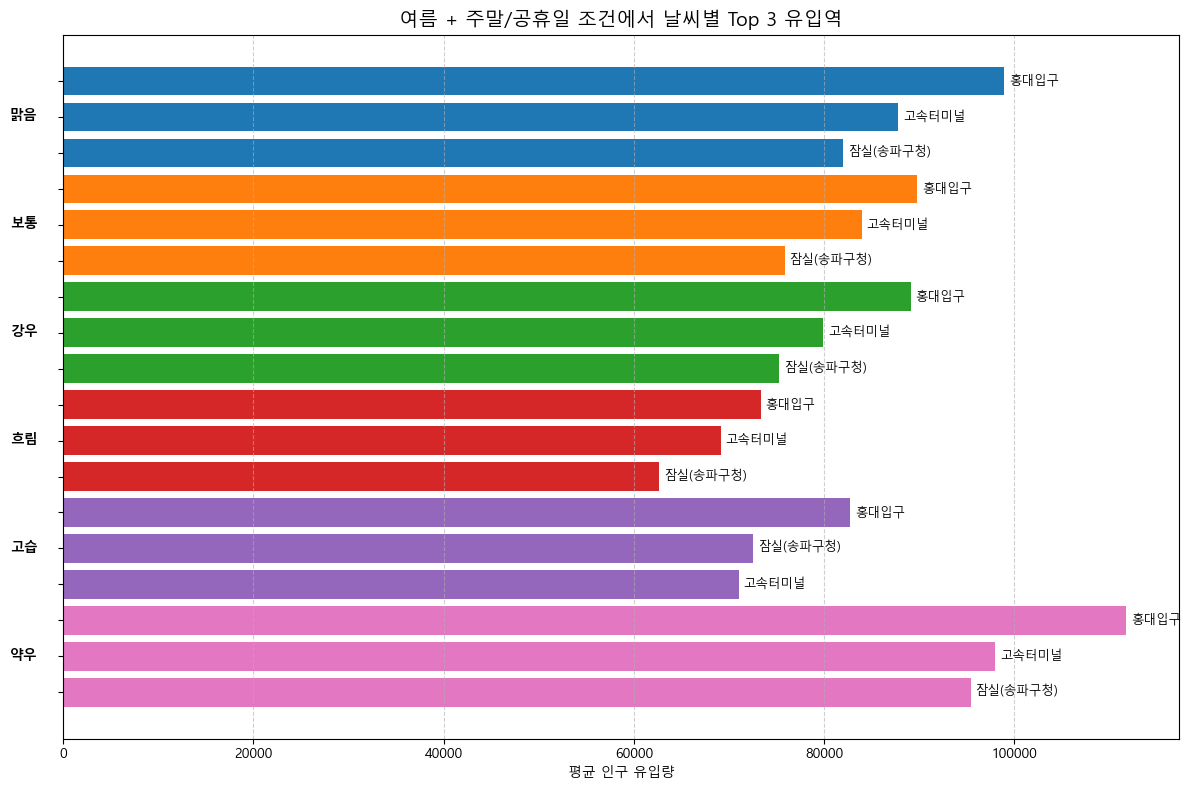

In [36]:
# ② 조건:여름 + 주말/공휴일 필터링
summer_weekend_df = df_filtered[
    (df_filtered['계절'] == '여름') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 날씨 유형별 Top 3 유입역 추출
weather_order = ['맑음', '보통', '강우', '흐림', '고습', '약우']
top3_data = []

for weather in weather_order:
    weather_df = summer_weekend_df[summer_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()
    top3 = avg_by_station.sort_values(ascending=False).head(3)
    for rank, (station, value) in enumerate(top3.items(), start=1):
        top3_data.append({
            '날씨': weather,
            '역명': station,
            '유입량': value,
            '순위': rank
        })

# ④ 데이터프레임 변환
top3_df = pd.DataFrame(top3_data)

# ⑤ 시각화: 막대그래프 (가로 막대, 역명 표시 포함)
plt.figure(figsize=(12, 8))

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '고습': '#9467bd',
    '약우': '#e377c2',
}

yticks = []
yticklabels = []
bar_positions = []

# ⑦ 막대 출력
for i, weather in enumerate(weather_order):
    group = top3_df[top3_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['유입량'], color=weather_colors[weather])
        plt.text(row['유입량'] + 500, y_pos, row['역명'], va='center', fontsize=9)  # 오른쪽에 역명
        bar_positions.append(y_pos)
     

# ⑧ y축 설정 및 정렬
plt.yticks(bar_positions, yticklabels)
plt.gca().invert_yaxis()
plt.xlabel('평균 인구 유입량')
plt.title('여름 + 주말/공휴일 조건에서 날씨별 Top 3 유입역', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(top3_df['유입량']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


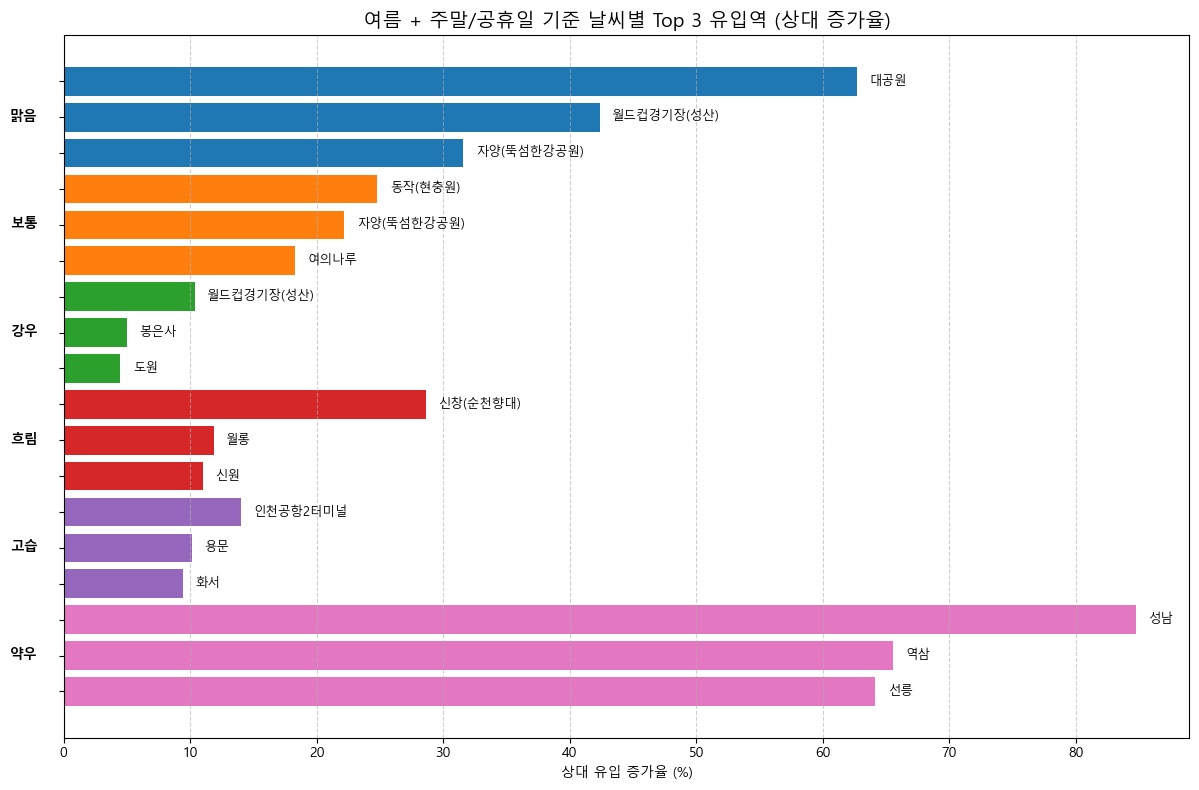

In [37]:
# ② 조건: 여름 + 주말/공휴일 필터링
summer_weekend_df = df_filtered[
    (df_filtered['계절'] == '여름') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 기준선: 여름+주말/공휴일 전체 평균 유입량
summer_avg_all = summer_weekend_df.groupby('역명')['인구유입량'].mean()

# ④ 날씨 유형별 상대 증가율 Top 3 계산
weather_order = ['맑음', '보통', '강우', '흐림', '고습', '약우']
relative_top3_data = []

for weather in weather_order:
    weather_df = summer_weekend_df[summer_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()

    # 공통 역 기준으로 상대증가율 계산
    common_stations = avg_by_station.index.intersection(summer_avg_all.index)
    relative_increase = (
        (avg_by_station[common_stations] - summer_avg_all[common_stations]) /
        summer_avg_all[common_stations]
    ) * 100

    top3 = relative_increase.sort_values(ascending=False).head(3)

    for rank, (station, value) in enumerate(top3.items(), start=1):
        relative_top3_data.append({
            '날씨': weather,
            '역명': station,
            '상대증가율': value,
            '순위': rank
        })

# ⑤ 데이터프레임 변환
relative_df = pd.DataFrame(relative_top3_data)

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '고습': '#9467bd',
    '약우': '#e377c2',
}

# ⑦ 시각화: 상대 유입 증가율
plt.figure(figsize=(12, 8))
bar_positions = []

for i, weather in enumerate(weather_order):
    group = relative_df[relative_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['상대증가율'], color=weather_colors[weather])
        plt.text(row['상대증가율'] + 1, y_pos, row['역명'], va='center', fontsize=9)
        bar_positions.append(y_pos)

# ⑧ y축 설정
plt.yticks(bar_positions, [])  # 개별 막대에는 텍스트 없음
plt.gca().invert_yaxis()
plt.xlabel('상대 유입 증가율 (%)')
plt.title('여름 + 주말/공휴일 기준 날씨별 Top 3 유입역 (상대 증가율)', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(relative_df['상대증가율']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5-3. 가을 날씨 유형 구분 기준 통합분석(절대, 상대)

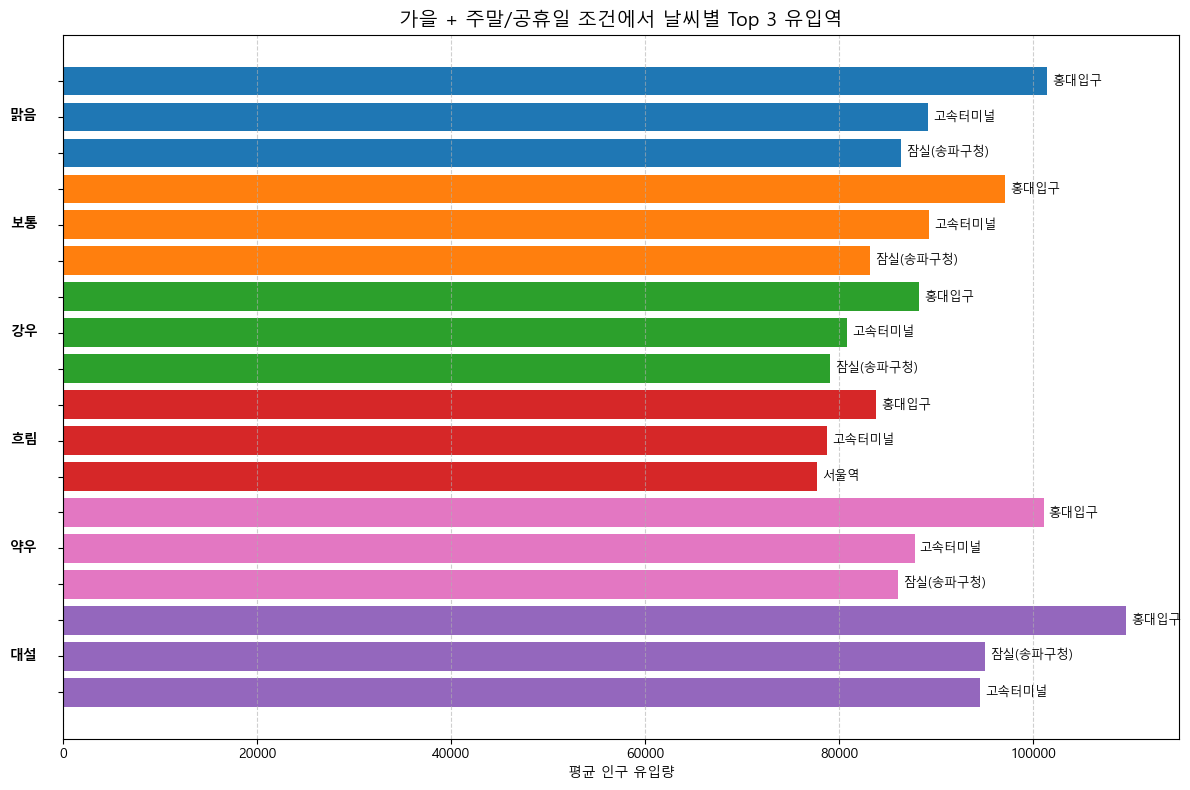

In [38]:
# ② 조건:가을 + 주말/공휴일 필터링
autumn_weekend_df = df_filtered[
    (df_filtered['계절'] == '가을') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 날씨 유형별 Top 3 유입역 추출
weather_order = ['맑음', '보통', '강우', '흐림', '약우','대설']
top3_data = []

for weather in weather_order:
    weather_df = autumn_weekend_df[autumn_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()
    top3 = avg_by_station.sort_values(ascending=False).head(3)
    for rank, (station, value) in enumerate(top3.items(), start=1):
        top3_data.append({
            '날씨': weather,
            '역명': station,
            '유입량': value,
            '순위': rank
        })

# ④ 데이터프레임 변환
top3_df = pd.DataFrame(top3_data)

# ⑤ 시각화: 막대그래프 (가로 막대, 역명 표시 포함)
plt.figure(figsize=(12, 8))

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '약우': '#e377c2',
    '대설': '#9467bd',
}

yticks = []
yticklabels = []
bar_positions = []

# ⑦ 막대 출력
for i, weather in enumerate(weather_order):
    group = top3_df[top3_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['유입량'], color=weather_colors[weather])
        plt.text(row['유입량'] + 500, y_pos, row['역명'], va='center', fontsize=9)  # 오른쪽에 역명
        bar_positions.append(y_pos)
     

# ⑧ y축 설정 및 정렬
plt.yticks(bar_positions, yticklabels)
plt.gca().invert_yaxis()
plt.xlabel('평균 인구 유입량')
plt.title('가을 + 주말/공휴일 조건에서 날씨별 Top 3 유입역', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(top3_df['유입량']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [39]:
# ① 가을 + 주말/공휴일 + 대설 날 필터링
autumn_snow_days = autumn_weekend_df[autumn_weekend_df['날씨 유형'] == '대설']

# ② 날짜 기준으로 중복 제거 (날짜 컬럼이 '일시'라고 가정)
unique_snow_dates = autumn_snow_days['일시'].drop_duplicates()

# ③ 출력
print(unique_snow_dates)


554344   2024-11-30
554865   2024-12-01
Name: 일시, dtype: datetime64[ns]


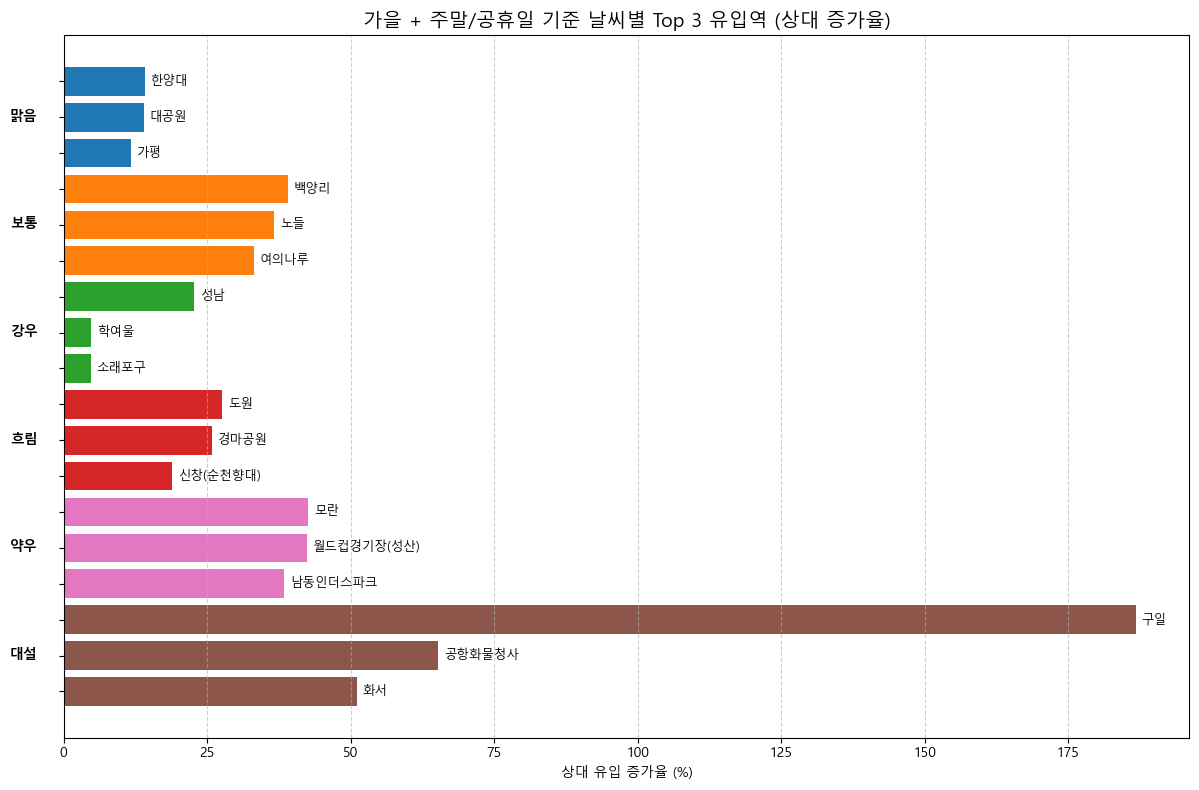

In [40]:
# ② 조건: 가을 + 주말/공휴일 필터링
autumn_weekend_df = df_filtered[
    (df_filtered['계절'] == '가을') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 기준선: 가을+주말/공휴일 전체 평균 유입량
autumn_avg_all = autumn_weekend_df.groupby('역명')['인구유입량'].mean()

# ④ 날씨 유형별 상대 증가율 Top 3 계산
weather_order = ['맑음', '보통', '강우', '흐림', '약우', '대설']
relative_top3_data = []

for weather in weather_order:
    weather_df = autumn_weekend_df[autumn_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()

    # 공통 역 기준으로 상대증가율 계산
    common_stations = avg_by_station.index.intersection(autumn_avg_all.index)
    relative_increase = (
        (avg_by_station[common_stations] - autumn_avg_all[common_stations]) /
        autumn_avg_all[common_stations]
    ) * 100

    top3 = relative_increase.sort_values(ascending=False).head(3)

    for rank, (station, value) in enumerate(top3.items(), start=1):
        relative_top3_data.append({
            '날씨': weather,
            '역명': station,
            '상대증가율': value,
            '순위': rank
        })

# ⑤ 데이터프레임 변환
relative_df = pd.DataFrame(relative_top3_data)

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '강우': '#2ca02c',
    '흐림': '#d62728',
    '약우': '#e377c2',
    '대설': '#8c564b',
}

# ⑦ 시각화: 상대 유입 증가율
plt.figure(figsize=(12, 8))
bar_positions = []

for i, weather in enumerate(weather_order):
    group = relative_df[relative_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['상대증가율'], color=weather_colors[weather])
        plt.text(row['상대증가율'] + 1, y_pos, row['역명'], va='center', fontsize=9)
        bar_positions.append(y_pos)

# ⑧ y축 설정
plt.yticks(bar_positions, [])  # 개별 막대에는 텍스트 없음
plt.gca().invert_yaxis()
plt.xlabel('상대 유입 증가율 (%)')
plt.title('가을 + 주말/공휴일 기준 날씨별 Top 3 유입역 (상대 증가율)', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(relative_df['상대증가율']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5-4. 겨울 날씨 유형 구분 기준 통합분석(절대, 상대)

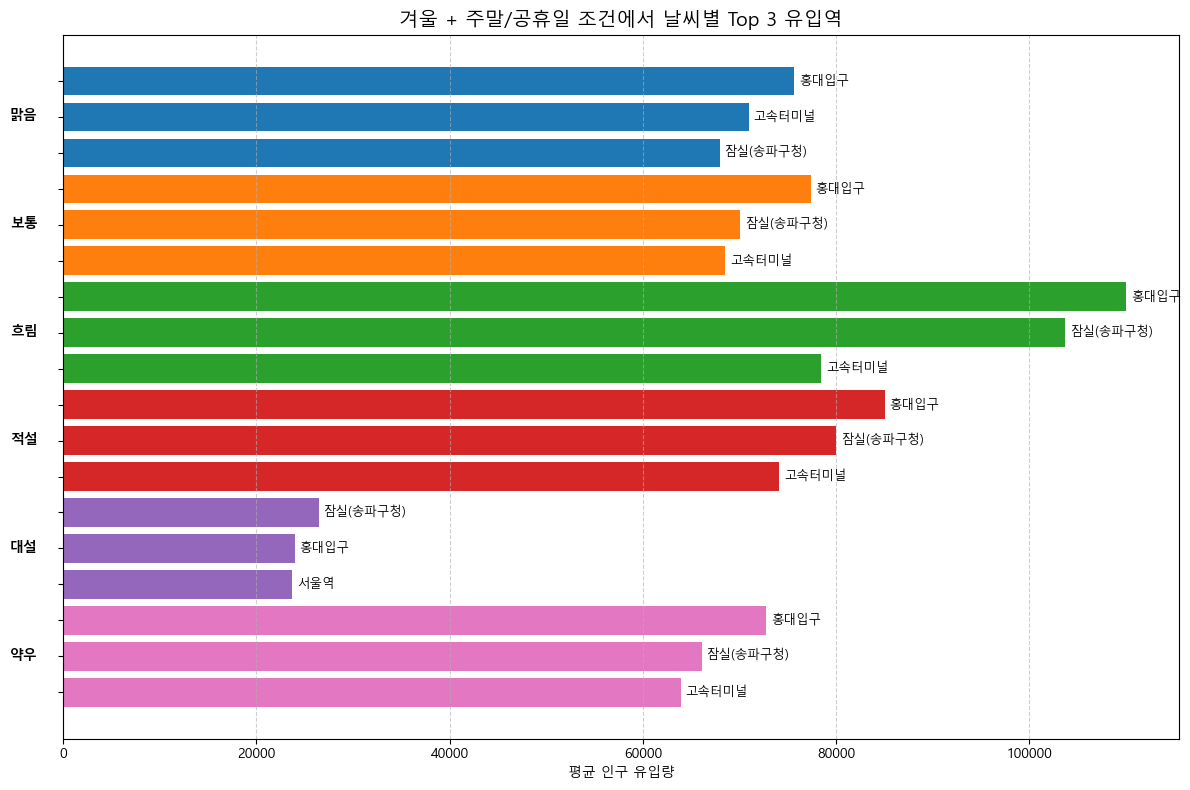

In [41]:
# ② 조건:겨울 + 주말/공휴일 필터링
winter_weekend_df = df_filtered[
    (df_filtered['계절'] == '겨울') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 날씨 유형별 Top 3 유입역 추출
weather_order = ['맑음', '보통', '흐림','적설', '대설', '약우']
top3_data = []

for weather in weather_order:
    weather_df = winter_weekend_df[winter_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()
    top3 = avg_by_station.sort_values(ascending=False).head(3)
    for rank, (station, value) in enumerate(top3.items(), start=1):
        top3_data.append({
            '날씨': weather,
            '역명': station,
            '유입량': value,
            '순위': rank
        })

# ④ 데이터프레임 변환
top3_df = pd.DataFrame(top3_data)

# ⑤ 시각화: 막대그래프 (가로 막대, 역명 표시 포함)
plt.figure(figsize=(12, 8))

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '흐림': '#2ca02c',
    '적설': '#d62728',
    '대설': '#9467bd',
    '약우': '#e377c2',
}

yticks = []
yticklabels = []
bar_positions = []

# ⑦ 막대 출력
for i, weather in enumerate(weather_order):
    group = top3_df[top3_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['유입량'], color=weather_colors[weather])
        plt.text(row['유입량'] + 500, y_pos, row['역명'], va='center', fontsize=9)  # 오른쪽에 역명
        bar_positions.append(y_pos)
     

# ⑧ y축 설정 및 정렬
plt.yticks(bar_positions, yticklabels)
plt.gca().invert_yaxis()
plt.xlabel('평균 인구 유입량')
plt.title('겨울 + 주말/공휴일 조건에서 날씨별 Top 3 유입역', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(top3_df['유입량']) * 0.05, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


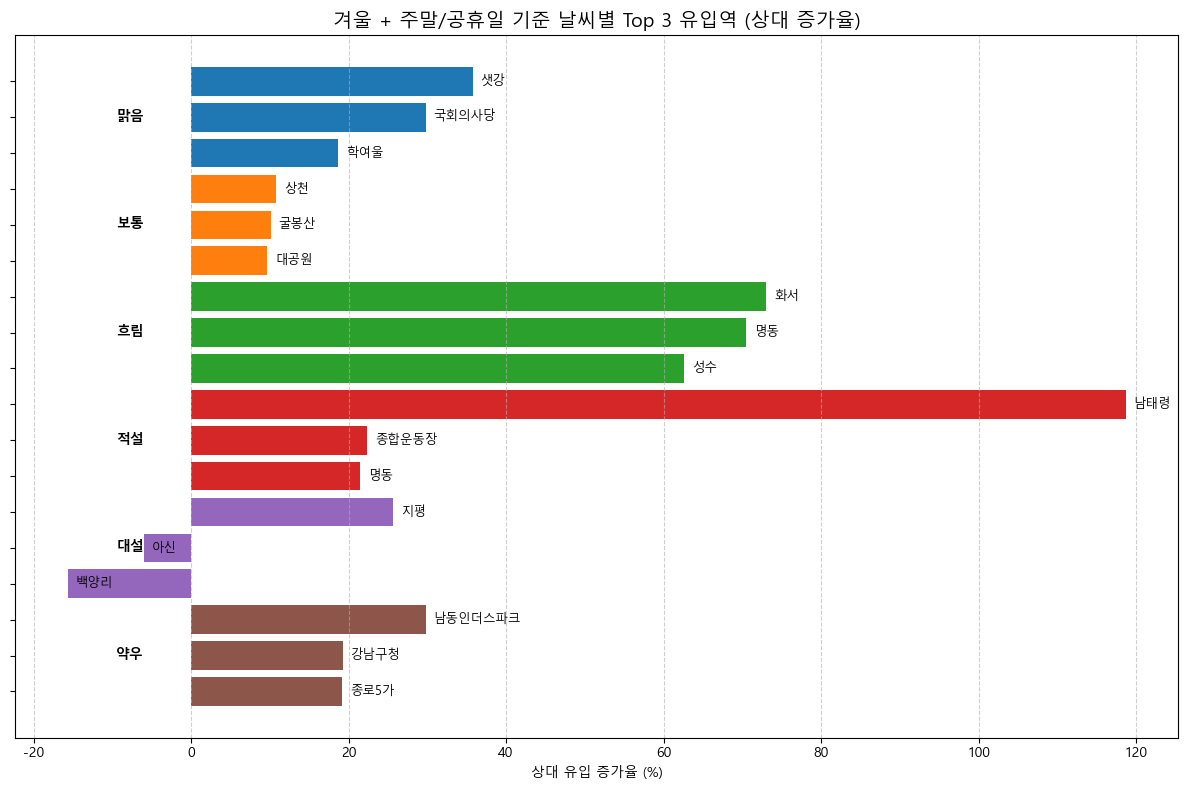

In [42]:
# ② 조건: 겨울 + 주말/공휴일 필터링
winter_weekend_df = df_filtered[
    (df_filtered['계절'] == '겨울') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ③ 기준선: 겨울+주말/공휴일 전체 평균 유입량
winter_avg_all = winter_weekend_df.groupby('역명')['인구유입량'].mean()

# ④ 날씨 유형별 상대 증가율 Top 3 계산
weather_order = ['맑음', '보통', '흐림', '적설', '대설', '약우']
relative_top3_data = []

for weather in weather_order:
    weather_df = winter_weekend_df[winter_weekend_df['날씨 유형'] == weather]
    avg_by_station = weather_df.groupby('역명')['인구유입량'].mean()

    # 공통 역 기준으로 상대증가율 계산
    common_stations = avg_by_station.index.intersection(winter_avg_all.index)
    relative_increase = (
        (avg_by_station[common_stations] - winter_avg_all[common_stations]) /
        winter_avg_all[common_stations]
    ) * 100

    top3 = relative_increase.sort_values(ascending=False).head(3)

    for rank, (station, value) in enumerate(top3.items(), start=1):
        relative_top3_data.append({
            '날씨': weather,
            '역명': station,
            '상대증가율': value,
            '순위': rank
        })

# ⑤ 데이터프레임 변환
relative_df = pd.DataFrame(relative_top3_data)

# ⑥ 색상 정의
weather_colors = {
    '맑음': '#1f77b4',
    '보통': '#ff7f0e',
    '흐림': '#2ca02c',
    '적설': '#d62728',
    '대설': '#9467bd',
    '약우': '#8c564b',
}

# ⑦ 시각화: 상대 유입 증가율
plt.figure(figsize=(12, 8))
bar_positions = []

for i, weather in enumerate(weather_order):
    group = relative_df[relative_df['날씨'] == weather]
    for j, (_, row) in enumerate(group.iterrows()):
        y_pos = i * 3 + j
        plt.barh(y_pos, row['상대증가율'], color=weather_colors[weather])
        plt.text(row['상대증가율'] + 1, y_pos, row['역명'], va='center', fontsize=9)
        bar_positions.append(y_pos)

# ⑧ y축 설정
plt.yticks(bar_positions, [])  # 개별 막대에는 텍스트 없음
plt.gca().invert_yaxis()
plt.xlabel('상대 유입 증가율 (%)')
plt.title('겨울 + 주말/공휴일 기준 날씨별 Top 3 유입역 (상대 증가율)', fontsize=14)

# ⑨ 왼쪽에 날씨 유형만 표시
for i, weather in enumerate(weather_order):
    plt.text(-max(relative_df['상대증가율']) * 0.08, i * 3 + 1, weather,
             va='center', fontsize=10, weight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [43]:
# ① 겨울 + 주말/공휴일 전체 평균 유입량 (기준선)
winter_weekend_df = df_filtered[
    (df_filtered['계절'] == '겨울') & (df_filtered['휴일 구분'] == '주말/공휴일')
]
winter_avg_all = winter_weekend_df.groupby('역명')['인구유입량'].mean()

# ② 겨울 + 주말/공휴일 + 대설 조건 필터링
snow_df = winter_weekend_df[winter_weekend_df['날씨 유형'] == '대설']
snow_avg_by_station = snow_df.groupby('역명')['인구유입량'].mean()

# ③ 공통 역에 대해 상대 유입 증가율 계산
common_stations = snow_avg_by_station.index.intersection(winter_avg_all.index)
relative_increase = (
    (snow_avg_by_station[common_stations] - winter_avg_all[common_stations]) /
    winter_avg_all[common_stations]
) * 100

# ④ Top 3 출력
top3_relative_snow = relative_increase.sort_values(ascending=False).head(3)

# ⑤ 결과 출력
print("❄️ 겨울 + 주말/공휴일 + 대설 조건에서 상대 유입 증가율 Top 3:")
print(top3_relative_snow)


❄️ 겨울 + 주말/공휴일 + 대설 조건에서 상대 유입 증가율 Top 3:
역명
지평     25.635104
아신     -6.019854
백양리   -15.653673
Name: 인구유입량, dtype: float64


# 5.5 봄의 날씨유형별 데이터에 대한 설명력

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import plotly.express as px
import plotly.io as pio
pio.renderers.default = 'browser'

# ① 봄 + 주말/공휴일 데이터 필터링
spring_weekend_df = df_filtered[
    (df_filtered['계절'] == '봄') & (df_filtered['휴일 구분'] == '주말/공휴일')
]

# ② 날씨 유형 목록
weather_types = spring_weekend_df['날씨 유형'].unique()

# ③ 역별 평균 유입량
station_avg = spring_weekend_df.groupby('역명')['인구유입량'].mean()

# ④ 날씨 유형별 분석 및 시각화
for weather in weather_types:
    results = []

    df_weather = spring_weekend_df.copy()
    df_weather['날씨더미'] = (df_weather['날씨 유형'] == weather).astype(int)

    for station in df_weather['역명'].unique():
        sub = df_weather[df_weather['역명'] == station]
        
        if len(sub) < 10:
            continue  # 샘플 수 부족한 역은 제외

        X = sub[['날씨더미']]
        y = sub['인구유입량']

        model = LinearRegression().fit(X, y)
        y_pred = model.predict(X)
        r2 = r2_score(y, y_pred)

        results.append({
            '역명': station,
            'R2': r2,
            '평균유입량': station_avg.get(station, 0)
        })
    
    r2_df = pd.DataFrame(results)
    r2_df['Top10'] = r2_df['R2'].rank(ascending=False, method='min') <= 10

    # ⑤ 산점도 시각화
    fig = px.scatter(
        r2_df,
        x='평균유입량',
        y='R2',
        hover_name='역명',
        color=r2_df['Top10'].map({True: 'Top 10', False: '기타'}),
        color_discrete_map={'Top 10': 'crimson', '기타': 'darkgray'},
        title=f"🌸 봄 + 주말/공휴일 - '{weather}' 날씨 여부에 따른 설명력 (R²) vs 평균 유입량",
        labels={'평균유입량': '역 평균 유입량', 'R2': '설명력 (R²)', 'color': '구분'},
        opacity=0.75
    )

    fig.update_traces(marker=dict(size=8))
    fig.update_layout(width=850, height=550)
    fig.show()